# DSC 530 Final Project — Film Representation and Box Office Performance, 1990–2015

**Ander (Trevor) McKee** · DSC530-T301 Data Exploration and Analysis · Summer 2026

---

**What the Bechdel test measures.** The Bechdel test is a measure of how women appear in a film. Level 1 is that the film has two named women; level 2 is that they speak to one another; level 3 is that they speak about something other than a man. Only level 3 is a pass.

**Research question.** Among commercially released US films from 1990 to 2015 with available dialogue data, how does a film's Bechdel test result relate to its box office performance, once production budget and release year are held fixed?

**The project data.** I've joined three independent public sources into one 798-film analysis table: (1) the Pudding film-dialogue data (character-level speech by gender), (2) bechdeltest.com's volunteer Bechdel ratings, and (3) The Numbers' production budgets and grosses. Acquisition, provenance, and known limitations are documented under Preliminary Preparation 1(b).

**Association, not causation.** The results below describe patterns, not effects. Nothing here supports a claim that changing a film's representation would change its revenue.

*Headings below follow the DSC 530 Final Project Guidelines exactly.*

In [42]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats

pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid")

INTERIM = Path.cwd().parent / "data" / "interim"
FIGS = Path.cwd().parent / "figures"

# spine and pud are earlier merge stages, used by the funnel in 1(b).
df = pd.read_csv(INTERIM / "analysis_table.csv")
spine = pd.read_csv(INTERIM / "spine.csv")
pud = pd.read_csv(INTERIM / "pudding_film.csv")

# Variables calculated here and reused throughout.
df["log_dom"] = np.log10(df["domestic_gross"])
df["log_ww"] = np.log10(df["worldwide_gross"])
df["log_budget"] = np.log10(df["production_budget"])
df["pass_"] = df["bechdel_pass"].astype(int)
df["pfd_10pp"] = df["pct_female_dialogue"] * 10   # 1 unit = 10 percentage points
df["year_c"] = df["year"] - 2000                  # centered for a readable intercept

core = ["production_budget", "domestic_gross", "worldwide_gross",
        "pct_female_dialogue", "pct_female_characters", "bechdel_rating"]

# Money columns scaled to $M.
MONEY = ["production_budget", "domestic_gross", "worldwide_gross"]
core_musd = df[core].copy()
core_musd[MONEY] /= 1e6
MUSD_LABELS = {c: (f"{c} ($M)" if c in MONEY else c) for c in core}

print(f"analysis table: {df.shape[0]} films x {df.shape[1]} columns, "
      f"{df['year'].min()}-{df['year'].max()}")

analysis table: 798 films x 29 columns, 1990-2015


---

# Preliminary Preparation Tasks

## 1. Dataset Selection

### a. Adequacy Check

The analysis table holds **798 films released 1990–2015**, each with a Bechdel rating, gender-coded dialogue measures, and production budget with domestic and worldwide gross. While there aren't as many films as I had hoped, 798 is large enough to support regression, classification, and clustering. They also contain every variable required by the research question: a representation measure (Bechdel rating, female dialogue share), an outcome (box office gross), and a control (production budget).

To say it plainly, the sample is **not** a random sample of all films. Each join favored larger, better-documented releases. I've done some work to quantify this imbalance, and I've tried to be honest about its limitations.

Coverage of the analysis sample:

films: 798
years: 1990-2015

budget range:          $450,000 - $306,000,000
domestic gross range:  $30,471 - $936,662,225
Bechdel pass rate:     49.5%

films per year (min/median/max): 8/31/58


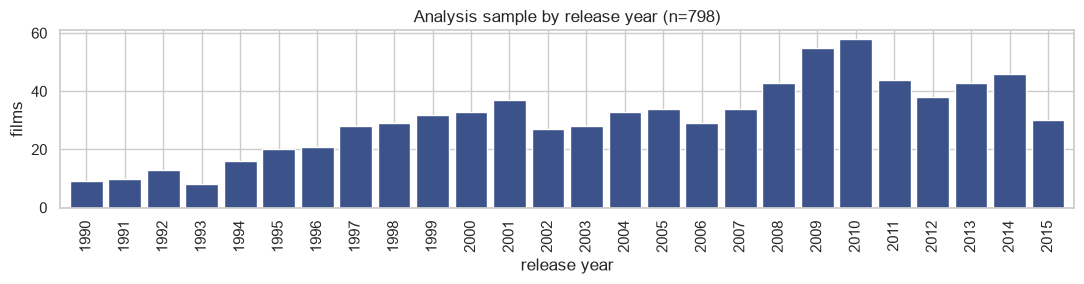

In [2]:
print("Coverage of the analysis sample:\n")
print(f"films: {len(df)}")
print(f"years: {df['year'].min()}-{df['year'].max()}")
print(f"\nbudget range:          ${df['production_budget'].min():,.0f} - ${df['production_budget'].max():,.0f}")
print(f"domestic gross range:  ${df['domestic_gross'].min():,.0f} - ${df['domestic_gross'].max():,.0f}")
print(f"Bechdel pass rate:     {df['bechdel_pass'].mean():.1%}")
print(f"\nfilms per year (min/median/max): "
      f"{df.groupby('year').size().min()}/{df.groupby('year').size().median():.0f}/{df.groupby('year').size().max()}")

# Films per release year.
fig, ax = plt.subplots(figsize=(11, 3))
df.groupby("year").size().plot.bar(ax=ax, width=0.85, color="#3b528b")
ax.set_ylabel("films"); ax.set_xlabel("release year")
ax.set_title(f"Analysis sample by release year (n={len(df)})")
fig.tight_layout()
fig.savefig(FIGS / "final_year_coverage.png", dpi=150)
plt.show()

### b. Data Integrity

#### Source information and collection:

| Source | What it has | How it was collected |
|---|---|---|
| **The Pudding** screenplay collection | character-level word counts with gender and age, 2,000 films | Screenplays scraped and parsed by Hanah Anderson & Matt Daniels (2016); characters gender-coded against IMDb cast lists |
| **bechdeltest.com** | Bechdel rating 0–3 per film | Submitted and reviewed by volunteers; accessed through the TidyTuesday 2021-03-09 mirror |
| **The Numbers** | production budget, domestic and worldwide gross | Industry reporting compiled by Nash Information Services; accessed through two static mirrors (TidyTuesday 2018, WWU DATA 311 2023) |

#### Known biases

1. **Volunteer rating.** Bechdel ratings are contributed by site visitors. Films that attract attention for representation reasons are more likely to be rated, and ratings can be disputed.
2. **Screenplay availability.** The Pudding data only covers films whose scripts were publicly available, which skews toward commercially successful English-language releases.
3. **Binary gender coding.** Characters are coded male/female against IMDb. IMDb does not referennce non-binary identities and can misclassify. There were five characters coded as `?`, all of whom were excluded during cleaning.
4. **Selection funnel.** Each time I joined a set, the sample got smaller and favored larger films.

**Variable-names.** There are two different measures of "gross" across sources: The Numbers reports **nominal** dollars, while the Pudding set reports **inflation-adjusted** dollars. The primary outcome uses nominal gross with a year control; the inflation-adjusted figure appears only as a check.

In [3]:
# The selection funnel.
pud_w = pud[pud["year"].between(1990, 2015)]
stages = {
    "1. Pudding window":   pud_w,
    "2. + Bechdel rated":  spine,
    "3. + budget matched": df,
}

# One row per merge stage.
funnel = pd.DataFrame({
    name: {
        "films": len(d),
        "mean $M": d["gross_infl_adj_musd"].mean(),
        "median $M": d["gross_infl_adj_musd"].median(),
        "% f. dialogue": 100 * d["pct_female_dialogue"].mean(),
    }
    for name, d in stages.items()
}).T

n = funnel["films"]
funnel.insert(1, "% kept", 100 * n / n.shift())        # of the previous stage
funnel.insert(2, "% of start", 100 * n / n.iloc[0])    # of the original 1,587
funnel["films"] = n.astype(int)

print("Selection funnel — every stage keeps larger films\n")
print(funnel.to_string(float_format=lambda v: f"{v:,.1f}", na_rep="—"))
print(f"\nNet loss: {int(n.iloc[0]):,} -> {int(n.iloc[-1]):,} films "
      f"({100*(1-n.iloc[-1]/n.iloc[0]):.1f}% dropped); "
      f"mean gross grew from ${funnel['mean $M'].iloc[0]:.0f}M -> ${funnel['mean $M'].iloc[-1]:.0f}M")

Selection funnel — every stage keeps larger films

                     films  % kept  % of start  mean $M  median $M  % f. dialogue
1. Pudding window     1587       —       100.0     92.9       50.0           29.0
2. + Bechdel rated    1189    74.9        74.9    105.9       62.0           30.0
3. + budget matched    798    67.1        50.3    124.9       80.0           28.3

Net loss: 1,587 -> 798 films (49.7% dropped); mean gross grew from $93M -> $125M


The funnel is the core limitation of this project, and I'm treating it more like a finding. The mean inflation-adjusted gross grows from **\\$93M → \\$106M → \\$125M**
across the joins. The films that remain are systematically bigger than the films get removed, so the estimates below describe *commercially successful, well-documented films*.

## 2. Data Cleaning and Preparation

### a. Handle missing values or outliers

**Missing values.** Four columns carry missing data. The pattern is structural; there's a visualizationn in EDA 2(b)(iii). I did not impute any data. The missing metadata columns are used only in a check. There is no good reason to impute a film's genre or MPAA rating here.

**Outliers.** I did not trim any observations. The extreme values in gross and budget are actual films; I verified against a second independent source, where cross-source gross. They do, however, skew the data, which is why I log transform in 2(c).

In [4]:
# Missing count and rate per column.
missing = df.isna().sum()
missing = missing[missing > 0].to_frame("missing")
missing["% of rows"] = 100 * missing["missing"] / len(df)
print("Columns with missing values:\n")
print(missing.to_string(float_format=lambda v: f"{v:,.1f}"))

complete = df.notna().all(axis=1).sum()
print(f"\nComplete rows across all columns: {complete} of {len(df)} ({100*complete/len(df):.1f}%)")

# Five largest grosses; ratio as a check.
top = df.nlargest(5, "domestic_gross")[
    ["title", "year", "production_budget", "domestic_gross"]].copy()
top["budget $M"] = top["production_budget"] / 1e6
top["domestic $M"] = top["domestic_gross"] / 1e6
top["gross/budget"] = top["domestic_gross"] / top["production_budget"]
top = top[["title", "year", "budget $M", "domestic $M", "gross/budget"]]

# Pad the header to left-align.
w = int(top["title"].str.len().max())
top = top.rename(columns={"title": f"{'title':<{w}}"})

print("\nOutlier check:\n")
print(top.to_string(index=False, formatters={
    f"{'title':<{w}}": lambda s: f"{s:<{w}}",
    "budget $M": lambda v: f"{v:,.1f}",
    "domestic $M": lambda v: f"{v:,.1f}",
    "gross/budget": lambda v: f"{v:.2f}x",
}))
print(f"\nMedian gross/budget across all {len(df)} films: "
      f"{(df['domestic_gross'] / df['production_budget']).median():.2f}x")

Columns with missing values:

                     missing  % of rows
gross_infl_adj_musd        9        1.1
distributor               87       10.9
mpaa_rating               87       10.9
genre                     87       10.9

Complete rows across all columns: 702 of 798 (88.0%)

Outlier check:

title                                       year budget $M domestic $M gross/budget
Star Wars: Episode VII - The Force Awakens  2015     306.0       936.7        3.06x
Avatar                                      2009     237.0       785.2        3.31x
Titanic                                     1997     200.0       666.1        3.33x
The Avengers                                2012     225.0       623.4        2.77x
The Dark Knight                             2008     185.0       535.0        2.89x

Median gross/budget across all 798 films: 1.39x


### b. Recoding or encoding of variables

Four derived variables are created. Each is a recoding decision:

| New variable | Derived from | Why |
|---|---|---|
| `bechdel_pass` / `pass_` | `bechdel_rating == 3` | The Bechdel test is usually read as pass/fail. Rating 3 means all three criteria are met. I kept this alongside the full 0–3 ordinal, which is used in a check. |
| `pfd_10pp` | `pct_female_dialogue × 10` | There is no film where women speak 100% of the dialogue. I rescale so one unit is a 10-percentage-point shift. A one-unit change in a 0–1 proportion would be the entire range. |
| `year_c` | `year − 2000` | Centering on the year 2,000 puts the intercept within the range of films. |
| `log_dom`, `log_ww`, `log_budget` | `log10` of each | See 2(c). |

Categorical variables (`genre`, `mpaa_rating`, `distributor`) are left as strings and encoded by `statsmodels` only where necessary, so the reference category stays the real string in the output.

In [5]:
# Confirm bechdel_pass is exactly rating == 3.
print("Encoding check — bechdel_rating (0-3 ordinal) to bechdel_pass (binary):\n")
print(pd.crosstab(df["bechdel_rating"], df["bechdel_pass"],
                  rownames=["bechdel_rating"], colnames=["bechdel_pass"]).to_string())
print(f"\npass rate: {df['bechdel_pass'].mean():.1%}  ({df['pass_'].sum()} of {len(df)} films)")
print(f"\npfd_10pp range: {df['pfd_10pp'].min():.2f} to {df['pfd_10pp'].max():.2f} "
      f"(one unit = 10 percentage points of dialogue)")

Encoding check — bechdel_rating (0-3 ordinal) to bechdel_pass (binary):

bechdel_pass    False  True 
bechdel_rating              
0                  49      0
1                 259      0
2                  95      0
3                   0    395

pass rate: 49.5%  (395 of 798 films)

pfd_10pp range: 0.00 to 9.19 (one unit = 10 percentage points of dialogue)


### c. Data transformation if certain variables are skewed or have extreme values

The three money variables are severely right-skewed (see EDA 2(a)): domestic gross has skewness 2.84 and kurtosis 13.40, and worldwide gross 3.66 and 23.40, against 0 for a normal distribution.

A **base-10 log transform** is applied to budget and both gross measures. Here is the justification:

1. Box office revenue is multiplicative (a film earns some *multiple* of its budget) so differences are naturally proportional.
2. If left untransformed, some blockbusters would dominate a least-squares fit.
3. On the log scale a regression coefficient reads as a **percentage** difference, which is how the result is reported.

`log10` is chosen over natural log for interpretability: one unit is one order of magnitude. `domestic_gross` has no
zero or negative values (minimum \\$30,471).

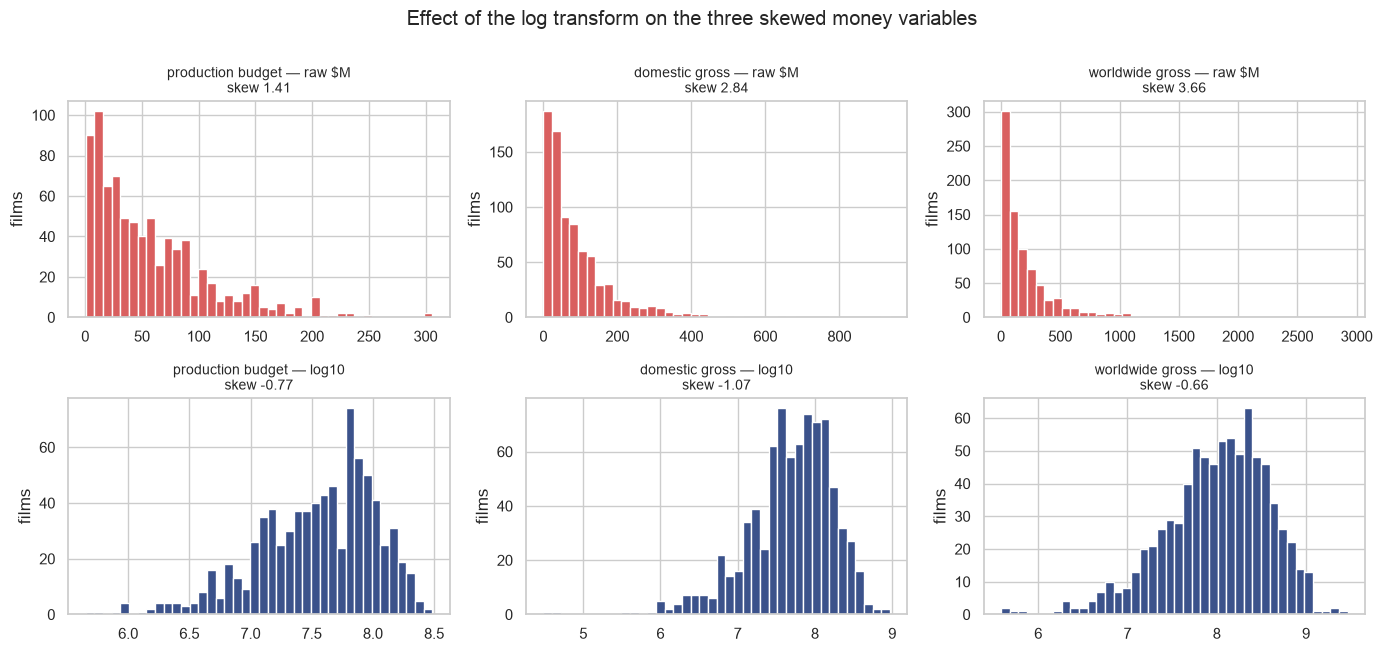

Skewness before and after the log10 transform:

                   raw skew  log10 skew
production_budget     1.407      -0.767
domestic_gross        2.841      -1.071
worldwide_gross       3.663      -0.661


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
# Top row raw scale, bottom row log10; one column per variable.
for j, (colname, label) in enumerate([("production_budget", "production budget"),
                                      ("domestic_gross", "domestic gross"),
                                      ("worldwide_gross", "worldwide gross")]):
    axes[0, j].hist(df[colname] / 1e6, bins=40, color="#d95f5f", edgecolor="white")
    axes[0, j].set_title(f"{label} — raw $M\nskew {df[colname].skew():.2f}", fontsize=10)
    axes[1, j].hist(np.log10(df[colname]), bins=40, color="#3b528b", edgecolor="white")
    axes[1, j].set_title(f"{label} — log10\nskew {np.log10(df[colname]).skew():.2f}", fontsize=10)
    for r in (0, 1):
        axes[r, j].set_ylabel("films")
fig.suptitle("Effect of the log transform on the three skewed money variables", y=1.00)
fig.tight_layout()
fig.savefig(FIGS / "final_log_transform.png", dpi=150)
plt.show()

print("Skewness before and after the log10 transform:\n")
print(pd.DataFrame({
    "raw skew": [df[c].skew() for c in ["production_budget", "domestic_gross", "worldwide_gross"]],
    "log10 skew": [np.log10(df[c]).skew() for c in ["production_budget", "domestic_gross", "worldwide_gross"]],
}, index=["production_budget", "domestic_gross", "worldwide_gross"]).round(3).to_string())

### d. Normalization or Standardization

Standardizing depends on the algorithm used, so it's decided per model:

- **Regression (5a) — not standardized.** Ordinary least squares is invariant to
  linear rescaling of its predictors: standardizing changes the coefficients and
  intercept but leaves fitted values, R², and p-values identical. Leaving budget on
  the log-dollar scale keeps the coefficients interpretable in real units.
- **Classification (5b) — standardized.** Regularized logistic regression penalizes
  the size of coefficients, so predictors on larger scales are penalized unfairly.
  Standardization is applied inside a `Pipeline` so it is fit on training folds only
  and cannot leak test information.
- **Clustering (6a) — standardized, and this one is mandatory.** k-means minimizes
  Euclidean distance. Without scaling, `production_budget` (spanning tens of
  millions) would completely determine the clusters and `pct_female_dialogue`
  (spanning 0 to 0.92) would contribute essentially nothing.

---

# Exploratory Data Analysis (EDA) Tasks

## 1. Describe the Variable Characteristics with Summary Statistics

### a. Provide description of the variables you are using in this project

The table below documents each column in the analysis table with its source and meaning.

In [7]:
data_dict = pd.read_csv(INTERIM / "data_dictionary.csv")
# Fail if the dictionary and the table disagree.
assert set(data_dict["column"]) == set(pd.read_csv(INTERIM / "analysis_table.csv").columns), \
    "data dictionary and analysis table have diverged"
print(f"Data dictionary — {len(data_dict)} columns, verified against the table")

display(data_dict.style.hide(axis="index")
        .set_properties(**{"text-align": "left"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))

Data dictionary — 23 columns, verified against the table


column,source,description
imdb_id,Pudding meta_data7,"IMDb id, tt+7 digits; primary key; join key for Bechdel"
script_id,Pudding,Pudding's internal film id (bridges character_list5 to meta_data7)
title,Pudding meta_data7,film title as recorded by Pudding
year,Pudding meta_data7,release year per Pudding; window filter 1990-2015 applied
gross_infl_adj_musd,Pudding meta_data7,"domestic gross, inflation-adjusted $M (2016 basis); robustness outcome only"
total_words,derived: character_list5,"sum of words over speaking characters (gender m/f, words>0)"
f_words,derived: character_list5,sum of words spoken by female-coded characters
n_characters,derived: character_list5,number of speaking characters after exclusions
n_female,derived: character_list5,number of female-coded speaking characters
pct_female_dialogue,derived,f_words / total_words (0-1); M2 predictor


In [8]:
# Money in $M to avoid scientific notation.
desc = core_musd.describe().T.drop(columns="count")
desc.index = [MUSD_LABELS[c] for c in core]

print(f"Summary statistics for the analysis variables (n = {len(df)} films)\n")
print(desc.to_string(float_format=lambda v: f"{v:,.2f}"))


Summary statistics for the analysis variables (n = 798 films)

                         mean    std  min   25%    50%    75%      max
production_budget ($M)  56.45  50.33 0.45 16.50  40.00  80.00   306.00
domestic_gross ($M)     88.58  98.73 0.03 25.63  56.45 119.35   936.66
worldwide_gross ($M)   202.74 262.17 0.38 46.09 112.42 258.51 2,923.71
pct_female_dialogue      0.28   0.20 0.00  0.13   0.23   0.39     0.92
pct_female_characters    0.31   0.16 0.00  0.20   0.30   0.42     0.89
bechdel_rating           2.05   1.03 0.00  1.00   2.00   3.00     3.00


## 2. Conduct Univariate Analysis

### a. Calculate descriptive statistics (mean, median, mode, variance, skewness, kurtosis)

In [9]:
# Money in $M, so variance is in ($M)^2.
moments = pd.DataFrame({
    "mean": core_musd.mean(),
    "median": core_musd.median(),
    "mode": core_musd.mode().iloc[0],
    "variance": core_musd.var(),
    "skewness": core_musd.skew(),
    "kurtosis": core_musd.kurt(),   # Fisher definition: 0 = normal, > 0 = heavy-tailed
})

# Set up rounding to two or three decimals.
two, three = (lambda v: f"{v:,.2f}"), (lambda v: f"{v:,.3f}")

print("Required descriptive statistics for the key variables")
print("(money variables in $M; variance in ($M)^2)\n")

# Print and apply rounding.
print(moments.rename(index=MUSD_LABELS).to_string(
    formatters={"mean": two, "median": two, "mode": two,
                "variance": three, "skewness": two, "kurtosis": two}))

# Count the mode.
print("\nFrequency of each mode")
for c in core:
    modal = moments.loc[c, "mode"]
    n = int((core_musd[c] == modal).sum())
    unit = " $M" if c in MONEY else ""
    if n == 1:
        # Declare if no mode (mode appears once).
        print(f"  {c:24s} no mode — no value occurs more than once")
    else:
        print(f"  {c:24s} mode {modal:>10,.4g}{unit:3s} occurs {n:3d}x of {len(df)}")


Required descriptive statistics for the key variables
(money variables in $M; variance in ($M)^2)

                         mean median  mode   variance skewness kurtosis
production_budget ($M)  56.45  40.00 35.00  2,532.855     1.41     2.18
domestic_gross ($M)     88.58  56.45  0.03  9,747.558     2.84    13.40
worldwide_gross ($M)   202.74 112.42  0.38 68,735.652     3.66    23.40
pct_female_dialogue      0.28   0.23  0.00      0.040     0.96     0.25
pct_female_characters    0.31   0.30  0.33      0.027     0.54     0.08
bechdel_rating           2.05   2.00  3.00      1.064    -0.43    -1.34

Frequency of each mode
  production_budget        mode         35 $M occurs  30x of 798
  domestic_gross           no mode — no value occurs more than once
  worldwide_gross          no mode — no value occurs more than once
  pct_female_dialogue      mode          0    occurs  18x of 798
  pct_female_characters    mode     0.3333    occurs  63x of 798
  bechdel_rating           mode          3

**My analysis**

The mode isn't very useful for the money variables, and the frequency explains. Domestic and worldwide gross are continuous, so every value is unique. Production budget is the exception because studios set budgets at round numbers. The mode is informative only for `bechdel_rating`, where 3 occurs 395 times.

Skewness and kurtosis are what justify the log transform of certain variables. Worldwide gross has skewness at 3.66 and kurtosis at 23.40, domestic gross at 2.84
and 13.40 (severe right tails).

### b. Create visualization of the key variables to examine distribution or patterns

#### i. Histograms, box plots, and density plots for numerical variables; bar charts for categorical

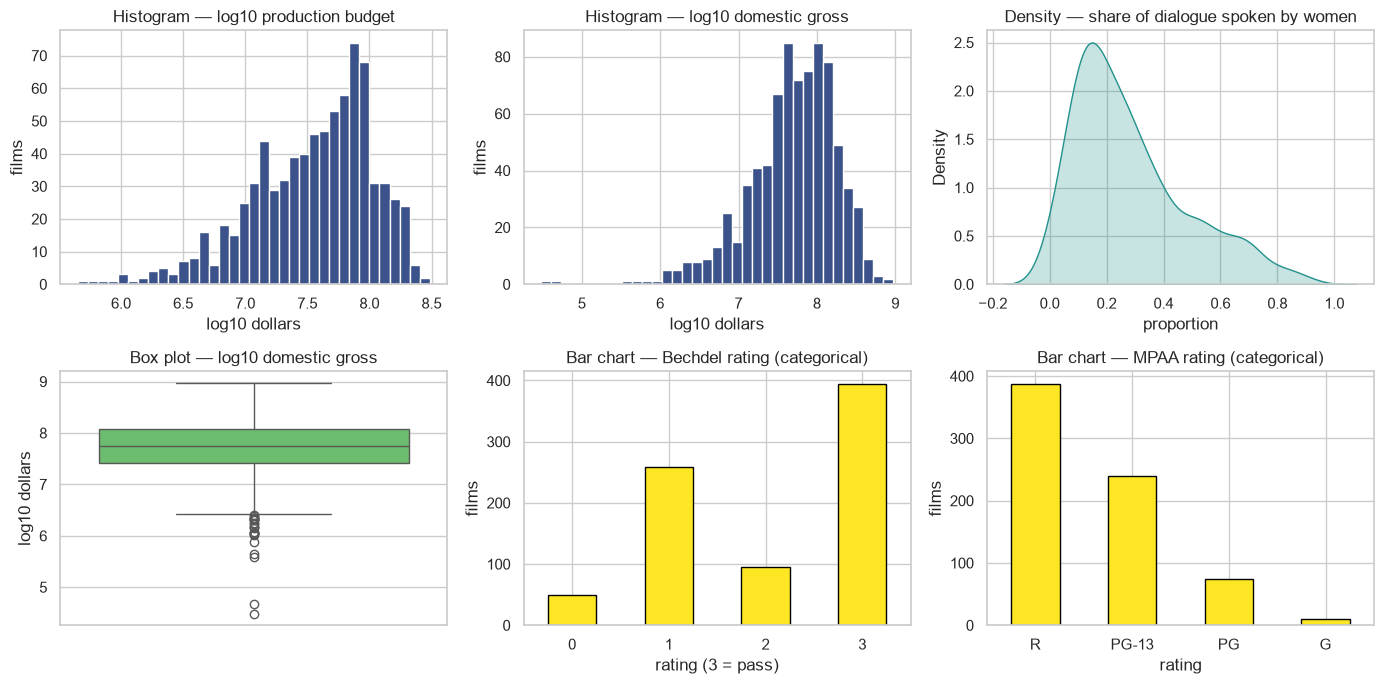

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

# One panel per required plot type: histogram, density, box, bar.
axes[0, 0].hist(df["log_budget"], bins=35, color="#3b528b", edgecolor="white")
axes[0, 0].set_title("Histogram — log10 production budget")
axes[0, 0].set_xlabel("log10 dollars"); axes[0, 0].set_ylabel("films")

axes[0, 1].hist(df["log_dom"], bins=35, color="#3b528b", edgecolor="white")
axes[0, 1].set_title("Histogram — log10 domestic gross")
axes[0, 1].set_xlabel("log10 dollars"); axes[0, 1].set_ylabel("films")

sns.kdeplot(data=df, x="pct_female_dialogue", fill=True, color="#21918c", ax=axes[0, 2])
axes[0, 2].set_title("Density — share of dialogue spoken by women")
axes[0, 2].set_xlabel("proportion")

sns.boxplot(data=df, y="log_dom", ax=axes[1, 0], color="#5ec962")
axes[1, 0].set_title("Box plot — log10 domestic gross")
axes[1, 0].set_ylabel("log10 dollars")

df["bechdel_rating"].value_counts().sort_index().plot.bar(
    ax=axes[1, 1], color="#fde725", edgecolor="black")
axes[1, 1].set_title("Bar chart — Bechdel rating (categorical)")
axes[1, 1].set_xlabel("rating (3 = pass)"); axes[1, 1].set_ylabel("films")
axes[1, 1].tick_params(axis="x", labelrotation=0)

df["mpaa_rating"].value_counts().plot.bar(ax=axes[1, 2], color="#fde725", edgecolor="black")
axes[1, 2].set_title("Bar chart — MPAA rating (categorical)")
axes[1, 2].set_xlabel("rating"); axes[1, 2].set_ylabel("films")
axes[1, 2].tick_params(axis="x", labelrotation=0)

fig.tight_layout()
fig.savefig(FIGS / "final_univariate.png", dpi=150)
plt.show()

The two log-scale histograms are nearly symmetric and unimodal, which meant the transform did well. Female dialogue share is right-skewed with a spike at zero (18 films have no female speech at all). The Bechdel bar chart shows most films at a rating of 1 or 3, and MPAA shows most films were rated R and PG-13.

#### ii. Visualizing outliers and skewness, and the method applied

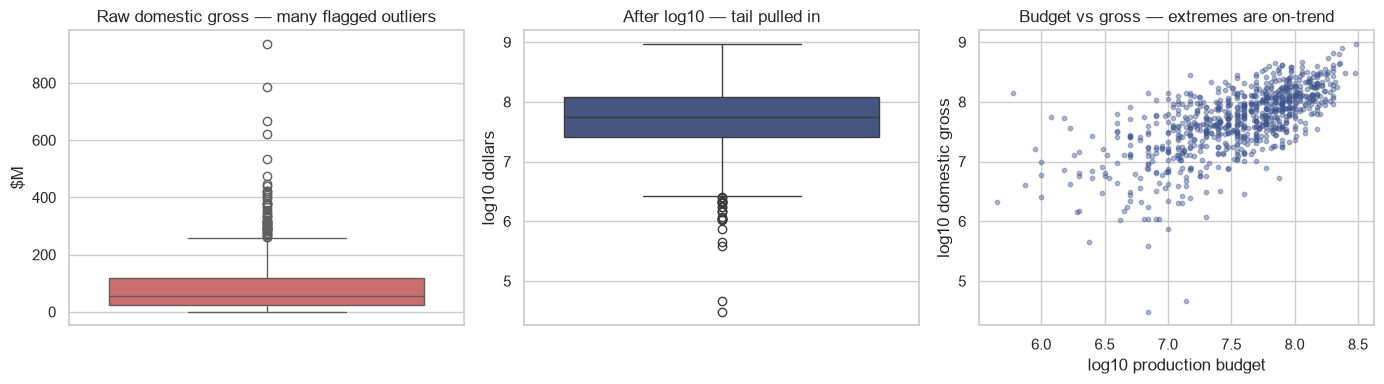

Points flagged as outliers by the 1.5 x IQR rule:

  domestic_gross, raw scale:    49 of 798
  domestic_gross, log10 scale:  24 of 798


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Same variable before and after log10, then budget vs gross.
sns.boxplot(data=df, y=df["domestic_gross"] / 1e6, ax=axes[0], color="#d95f5f")
axes[0].set_title("Raw domestic gross — many flagged outliers")
axes[0].set_ylabel("$M")

sns.boxplot(data=df, y="log_dom", ax=axes[1], color="#3b528b")
axes[1].set_title("After log10 — tail pulled in")
axes[1].set_ylabel("log10 dollars")

axes[2].scatter(df["log_budget"], df["log_dom"], s=10, alpha=0.4, color="#3b528b")
axes[2].set_xlabel("log10 production budget"); axes[2].set_ylabel("log10 domestic gross")
axes[2].set_title("Budget vs gross — extremes are on-trend")

fig.tight_layout()
fig.savefig(FIGS / "final_outliers.png", dpi=150)
plt.show()

# Count points outside 1.5 x IQR.
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

print("Points flagged as outliers by the 1.5 x IQR rule:\n")
print(f"  domestic_gross, raw scale:   {iqr_outliers(df['domestic_gross']):3d} of {len(df)}")
print(f"  domestic_gross, log10 scale: {iqr_outliers(df['log_dom']):3d} of {len(df)}")

No observations are removed. Even though the raw-scale box plot flags a large number of films as outliers, the scatter plot explains why that's misleading: the high-grossing films sit on trend with high budget–gross. They are films that spend big and earn proportionally; they are not invalid data.

The 1.5 × IQR rule works well on a roughly symmetric distribution, so on a right-skewed distribution, you mostly just detect the skew. Applying the log transform reduces flagged outliers. So the **method used is transformation, not trimming**.

#### iii. Visualize missing data to identify patterns in missingness

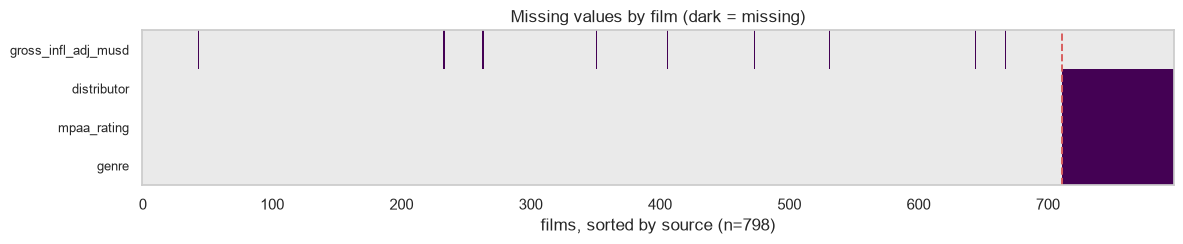

In [45]:
miss_cols = df.columns[df.isna().any()].tolist()
ordered = df.sort_values("source").reset_index(drop=True)

# Transposed so there are enough pixels for the range of films.
missing_matrix = ordered[miss_cols].isna().to_numpy().T

fig, ax = plt.subplots(figsize=(12, 2.6))
ax.imshow(missing_matrix, aspect="auto", interpolation="nearest",
          cmap=matplotlib.colors.ListedColormap(["#eaeaea", "#440154"]))

# Draw red boundary line.
boundary = int((ordered["source"] == "tidytuesday_2018").sum())
ax.axvline(boundary, color="#d95f5f", lw=1.4, ls="--")

ax.set_yticks(range(len(miss_cols)))
ax.set_yticklabels(miss_cols, fontsize=9)
ax.set_xlabel(f"films, sorted by source (n={len(df)})")
ax.set_title("Missing values by film (dark = missing)")
ax.grid(False)
fig.tight_layout()
fig.savefig(FIGS / "final_missingness.png", dpi=150)
plt.show()

**The missingness does not appear to be critical.** All 87 films missing `distributor`, `mpaa_rating`, and `genre` are missing all three at the same time. They're all from the `wwu_mirror_2023`.

This is an issue with the mirror, because its pages only had rank, date, title, budget, and the two grosses. These aren't films that just decline to report a genre. Since the missingness is explainable by the datasets, there is little practical consequence. The genre check simply runs on the 711 films that include ratings. Additionally, the 9 films that are missing `gross_infl_adj_musd` values come from random gaps in the Pudding data. They are not systematically missing and can be ignored.

## 3. Conduct Bivariate Analysis

### a. Calculate covariance and correlation

#### i. Pearson correlation for continuous values

In [13]:
def mask_lower(frame):
    """Blank the lower-left triangle; the matrix is symmetric so it repeats."""
    return frame.where(~np.tril(np.ones(frame.shape, dtype=bool), k=-1))


# Money already in $M (see setup), so covariance is readable.
print("Covariance matrix (money variables in $M, so those cells are in ($M)^2):\n")
print(mask_lower(core_musd.cov()).rename(index=MUSD_LABELS, columns=MUSD_LABELS)
      .to_string(float_format=lambda v: f"{v:,.3f}", na_rep=""))

print("\n\nPearson correlation matrix (the same information rescaled to [-1, 1]):\n")
print(mask_lower(core_musd.corr()).rename(index=MUSD_LABELS, columns=MUSD_LABELS)
      .to_string(float_format=lambda v: f"{v:.3f}", na_rep=""))

# Correlation is covariance divided by both standard deviations, so the first
# table is the numerator of the second. Worked through for one pair.
sd = core_musd.std()
a, b = "production_budget", "domestic_gross"
cov_ab = core_musd.cov().loc[a, b]
print("\n\nWhere the correlation comes from:\n")
print(f"  cov({a}, {b}) = {cov_ab:,.3f} ($M)^2")
print(f"  divided by sd({a}) x sd({b}) = {sd[a]:,.3f} x {sd[b]:,.3f}")
print(f"  gives {cov_ab / (sd[a] * sd[b]):.3f}, the reported correlation "
      f"of {core_musd.corr().loc[a, b]:.3f}")

# Within the money columns the units match, so the magnitudes are comparable.
print("\n\nCovariance among the money variables alone, all in ($M)^2:\n")
print(core_musd[MONEY].cov().to_string(float_format=lambda v: f"{v:,.0f}"))


Covariance matrix (money variables in $M, so those cells are in ($M)^2):

                        production_budget ($M)  domestic_gross ($M)  worldwide_gross ($M)  pct_female_dialogue  pct_female_characters  bechdel_rating
production_budget ($M)               2,532.855            3,241.406             9,170.306               -2.221                 -2.283          -6.150
domestic_gross ($M)                                       9,747.558            24,597.197               -2.488                 -2.815           2.044
worldwide_gross ($M)                                                           68,735.652               -6.216                 -7.665           5.271
pct_female_dialogue                                                                                      0.040                  0.025           0.113
pct_female_characters                                                                                                           0.027           0.083
bechdel_rating            

**Covariance and correlation carry the same information in different units.**
Covariance is measured in the product of the two variables' units, so values from
different pairs cannot be compared: the budget–gross covariance is 3,241 ($M)²,
while the dialogue–characters covariance is 0.025, a squared proportion. Neither
number means anything placed next to the other.

Correlation strips the units out by dividing covariance by both standard
deviations, which is what bounds it to [−1, 1]. The worked example above shows the
arithmetic on one pair: 3,241.406 ÷ (50.327 × 98.730) = 0.652, exactly the
reported correlation. **The covariance matrix is the numerator of the correlation
matrix**, which is why both are reported here but only correlation is used in the
discussion.

**Covariance still says one thing correlation does not.** Within the three money
variables the units match, so those magnitudes *are* directly comparable. Budget
covaries about 2.8× more with worldwide gross (9,170) than with domestic gross
(3,241), even though the two correlations are nearly identical at 0.695 and 0.652.
Correlation normalises away the fact that worldwide revenue is simply a larger
quantity with more room to move.

Three relationships matter for the analysis:

- **Budget and gross are strongly related** (r = 0.652 domestic, 0.695 worldwide).
  This is the confounder the design has to control for.
- **Budget and female dialogue share are negatively related** (r = −0.220), and
  budget correlates negatively with Bechdel rating too (r = −0.118). Bigger films
  give women less of the dialogue.
- Those two facts together are the setup for a suppression effect: budget pushes
  gross up and representation down, so failing to control for it hides any
  representation–gross relationship.


#### ii. Spearman rank correlation for the ordinal variable (Optional)

In [14]:
def mask_lower(frame):
    """Blank the lower-left triangle; the matrix is symmetric so it repeats."""
    return frame.where(~np.tril(np.ones(frame.shape, dtype=bool), k=-1))


# Spearman ranks the values, so no scaling is needed.
spear = df[core].corr(method="spearman")
print("Spearman rank correlation — appropriate for bechdel_rating, which is ordinal\n")
print(mask_lower(spear).to_string(float_format=lambda v: f"{v:.3f}", na_rep=""))

cmp = pd.DataFrame({
    "Pearson": df[core].corr()["bechdel_rating"],
    "Spearman": spear["bechdel_rating"],
}).drop("bechdel_rating")
cmp["difference"] = cmp["Spearman"] - cmp["Pearson"]

print("\n\nPearson vs Spearman for bechdel_rating specifically:\n")
print(cmp.to_string(float_format=lambda v: f"{v:+.3f}"))

Spearman rank correlation — appropriate for bechdel_rating, which is ordinal

                       production_budget  domestic_gross  worldwide_gross  pct_female_dialogue  pct_female_characters  bechdel_rating
production_budget                  1.000           0.682            0.731               -0.234                 -0.325          -0.165
domestic_gross                                     1.000            0.955               -0.162                 -0.214          -0.032
worldwide_gross                                                     1.000               -0.163                 -0.231          -0.051
pct_female_dialogue                                                                      1.000                  0.732           0.580
pct_female_characters                                                                                           1.000           0.498
bechdel_rating                                                                                                        

Spearman is the more defensible choice for `bechdel_rating` because the variable is
ordinal: the distance from rating 0 to 1 is not necessarily the same as from 2 to
3, and Pearson assumes it is. Spearman only uses rank order, so it makes no such
assumption. The two agree closely on sign and rough magnitude here, which is
reassuring, and the rank-based figures are slightly stronger for the dialogue
measures.

### b. Create visualization

#### i. Scatter plots, pair plots, and a correlation heatmap

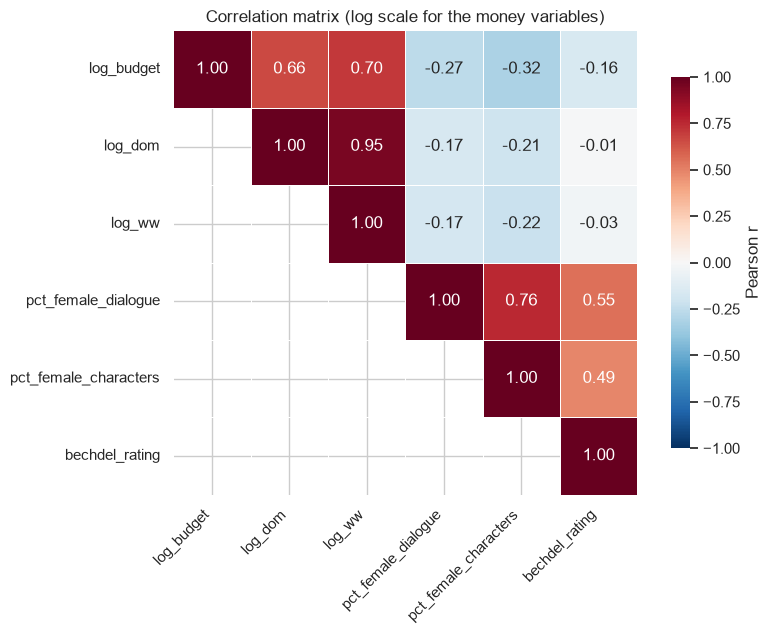

In [15]:
corr_vars = ["log_budget", "log_dom", "log_ww", "pct_female_dialogue",
             "pct_female_characters", "bechdel_rating"]

corr = df[corr_vars].corr()

# A correlation matrix is symmetric, so the lower-left triangle repeats every
# value already shown in the upper right. Masking it halves the number of cells
# the reader has to scan. k=-1 keeps the diagonal as a visual anchor.
mask = np.tril(np.ones_like(corr, dtype=bool), k=-1)

fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, square=True, ax=ax, linewidths=0.5,
            cbar_kws={"label": "Pearson r", "shrink": 0.8})
ax.set_title("Correlation matrix (log scale for the money variables)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
fig.tight_layout()
fig.savefig(FIGS / "final_corr_heatmap.png", dpi=150)
plt.show()

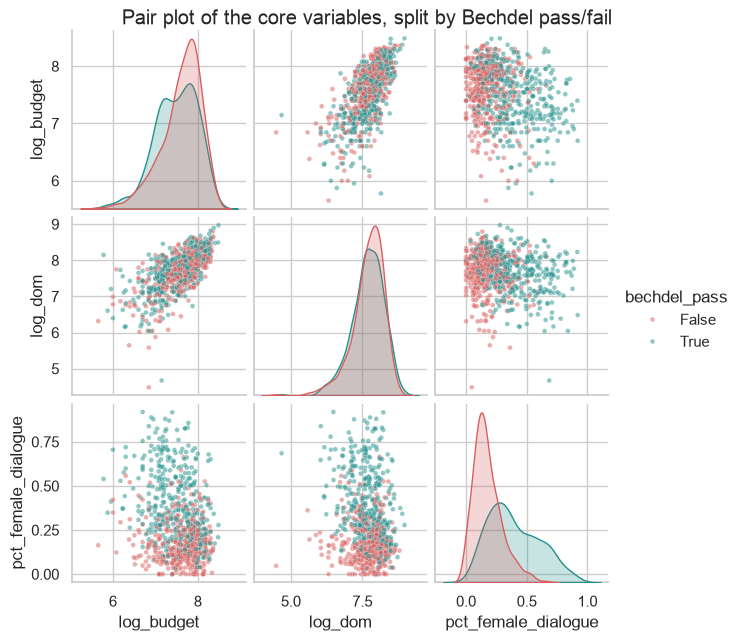

In [16]:
pair = sns.pairplot(df[["log_budget", "log_dom", "pct_female_dialogue", "bechdel_pass"]],
                    hue="bechdel_pass", palette={True: "#21918c", False: "#d95f5f"},
                    plot_kws={"s": 12, "alpha": 0.5}, height=2.1)
pair.figure.suptitle("Pair plot of the core variables, split by Bechdel pass/fail", y=1.01)
pair.savefig(FIGS / "final_pairplot.png", dpi=150)
plt.show()

#### ii. Advanced visualization with Seaborn (Optional)

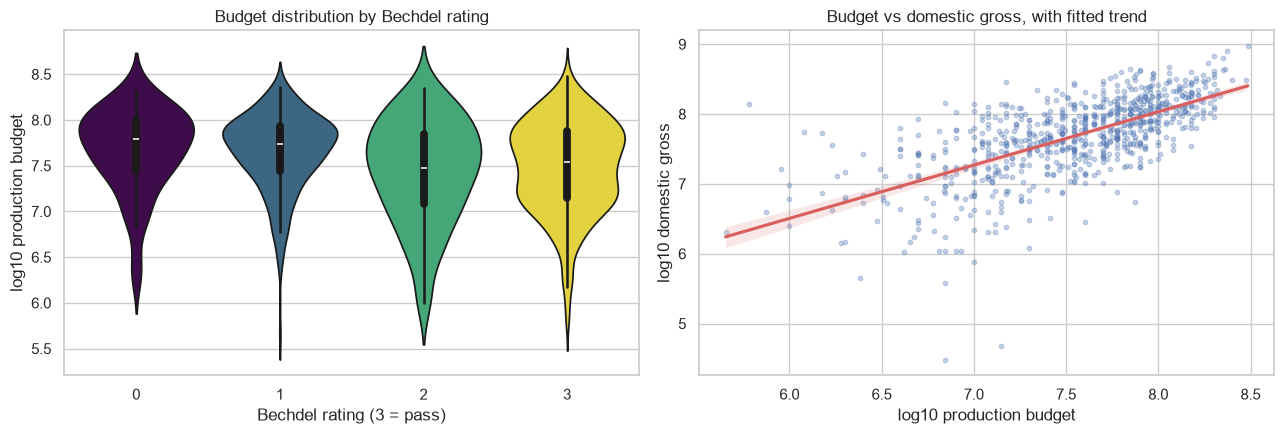

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.violinplot(data=df, x="bechdel_rating", y="log_budget", ax=axes[0],
               hue="bechdel_rating", palette="viridis", legend=False)
axes[0].set_title("Budget distribution by Bechdel rating")
axes[0].set_xlabel("Bechdel rating (3 = pass)"); axes[0].set_ylabel("log10 production budget")

sns.regplot(data=df, x="log_budget", y="log_dom", scatter_kws={"s": 10, "alpha": 0.3},
            line_kws={"color": "#d95f5f"}, ax=axes[1])
axes[1].set_title("Budget vs domestic gross, with fitted trend")
axes[1].set_xlabel("log10 production budget"); axes[1].set_ylabel("log10 domestic gross")

fig.tight_layout()
fig.savefig(FIGS / "final_seaborn_advanced.png", dpi=150)
plt.show()

The violin plot makes the confounder visible directly: budget falls monotonically
as Bechdel rating rises. Films rated 0 are the most expensive group, films rated 3
the least. This single panel is the mechanism behind the suppression result in
5(a) — passing films are handed smaller budgets, and budget drives gross.

## 4. Test Statistics

### a. Develop a hypothesis and select the appropriate test statistics

**Hypothesis 1 — continuous outcome, two independent groups.**

- **H₀:** mean log₁₀ domestic gross is equal for films that pass the Bechdel test
  and films that fail it.
- **H₁:** the two means differ.
- **α = 0.05**, two-tailed.

**Test selected: Welch's two-sample t-test.** The comparison is between the means
of one continuous variable across two independent, unpaired groups, which is
exactly what a two-sample t-test is for. Welch's variant is used rather than
Student's because it does not assume the two groups share a variance — it costs
almost nothing in power when variances *are* equal, so it is the safer default.
The test runs on the **log** scale, since 2(c) established that is where the
variable is approximately symmetric.

**Hypothesis 2 — two categorical variables.**

- **H₀:** Bechdel pass/fail is independent of MPAA rating.
- **H₁:** the two are associated.

**Test selected: Pearson's chi-squared test of independence**, the standard test
for association in a contingency table of two categorical variables.

A **Mann-Whitney U test** is also reported as a non-parametric check on Hypothesis
1, for reasons that 4(b) makes clear.

In [18]:
# Split log gross into the two Bechdel groups.
grp_pass = df.loc[df["bechdel_pass"], "log_dom"]
grp_fail = df.loc[~df["bechdel_pass"], "log_dom"]

print("Group summaries — log10 domestic gross\n")
print(pd.DataFrame({
    "n": [len(grp_pass), len(grp_fail)],
    "mean": [grp_pass.mean(), grp_fail.mean()],
    "std": [grp_pass.std(), grp_fail.std()],
    "median": [grp_pass.median(), grp_fail.median()],
}, index=["Bechdel pass", "Bechdel fail"]).round(4).to_string())

Group summaries — log10 domestic gross

                n    mean     std  median
Bechdel pass  395  7.6766  0.5627  7.7193
Bechdel fail  403  7.6904  0.5584  7.7844


### b. Assumptions of each test, and whether they hold

In [19]:
print("ASSUMPTION 1 — normality within each group (Shapiro-Wilk)")
print("  H0: the group is drawn from a normal distribution\n")
for name, s in [("pass", grp_pass), ("fail", grp_fail)]:
    W, p = stats.shapiro(s)
    verdict = "REJECT normality" if p < 0.05 else "cannot reject"
    print(f"  {name}: W = {W:.4f}, p = {p:.3g}  -> {verdict}"
          f"   (skew {s.skew():+.3f}, kurtosis {s.kurt():+.3f})")

print("\n\nASSUMPTION 2 — equal variances (Levene's test, median-centered)")
print("  H0: the two groups have equal variance\n")
L, pL = stats.levene(grp_pass, grp_fail, center="median")
verdict = "REJECT equal variance" if pL < 0.05 else "cannot reject - equal variance is tenable"
print(f"  Levene W = {L:.4f}, p = {pL:.4f}  -> {verdict}")
print(f"  variance ratio (pass/fail) = {grp_pass.var() / grp_fail.var():.3f}")

print("\n\nASSUMPTION 3 — independence of observations")
print(f"  Each row is a distinct film; no film appears twice: "
      f"{df['imdb_id'].is_unique}")

ASSUMPTION 1 — normality within each group (Shapiro-Wilk)
  H0: the group is drawn from a normal distribution

  pass: W = 0.9676, p = 1.13e-07  -> REJECT normality   (skew -0.807, kurtosis +1.806)
  fail: W = 0.9229, p = 1.58e-13  -> REJECT normality   (skew -1.341, kurtosis +3.431)


ASSUMPTION 2 — equal variances (Levene's test, median-centered)
  H0: the two groups have equal variance

  Levene W = 0.6852, p = 0.4080  -> cannot reject - equal variance is tenable
  variance ratio (pass/fail) = 1.016


ASSUMPTION 3 — independence of observations
  Each row is a distinct film; no film appears twice: True


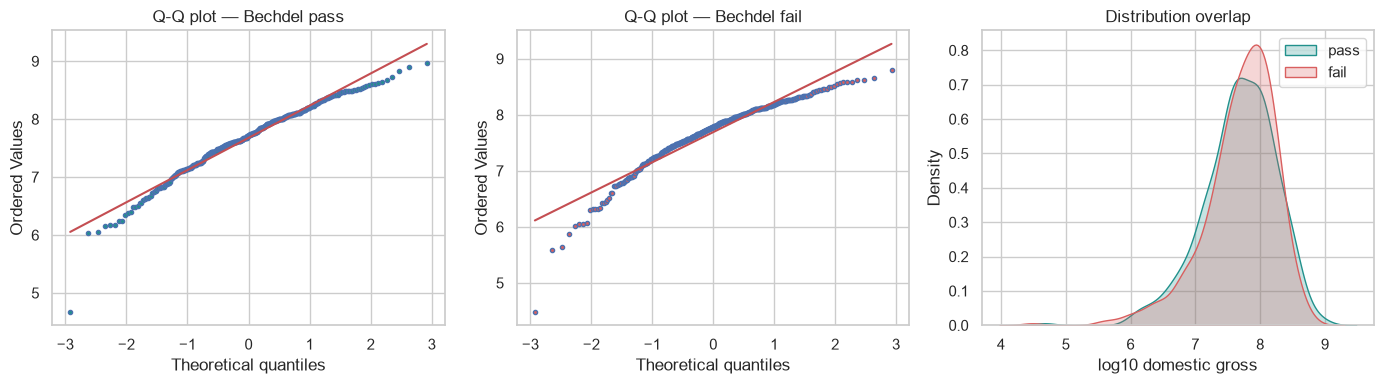

In [20]:
# Visual check on normality, since Shapiro-Wilk is very sensitive at large n.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, s, colour) in zip(axes[:2],
                                 [("Bechdel pass", grp_pass, "#21918c"),
                                  ("Bechdel fail", grp_fail, "#d95f5f")]):
    stats.probplot(s, dist="norm", plot=ax)
    ax.get_lines()[0].set_markerfacecolor(colour)
    ax.get_lines()[0].set_markersize(3.0)
    ax.set_title(f"Q-Q plot — {name}")

sns.kdeplot(x=grp_pass, fill=True, label="pass", color="#21918c", ax=axes[2])
sns.kdeplot(x=grp_fail, fill=True, label="fail", color="#d95f5f", ax=axes[2])
axes[2].set_title("Distribution overlap"); axes[2].set_xlabel("log10 domestic gross")
axes[2].legend()
fig.tight_layout()
fig.savefig(FIGS / "final_test_assumptions.png", dpi=150)
plt.show()

**Do the assumptions hold? Partly — and the honest answer changes what can be
concluded.**

- **Normality is formally violated.** Shapiro-Wilk rejects for both groups
  (p < 10⁻⁶). The Q-Q plots show why: both groups are left-skewed on the log scale
  (−0.81 and −1.34) with a tail of low-grossing films departing from the diagonal at
  the bottom left.
- **However, the violation is not fatal here.** The t-test relies on the sampling
  distribution of the *mean* being normal, not the data itself. With n = 395 and
  n = 403, the Central Limit Theorem makes that sampling distribution approximately
  normal despite the skew. Shapiro-Wilk is also known to reject on trivial
  departures at large sample sizes, so a significant result from it is weak evidence
  of a practical problem. To confirm the conclusion does not depend on this, a
  **Mann-Whitney U test** — which assumes no distributional form — is reported
  alongside.
- **Equal variance holds.** Levene's test does not reject (p = 0.408) and the
  variance ratio is 1.016. Welch's correction was therefore unnecessary, but
  harmless — it is used anyway rather than switching tests after seeing the result.
- **Independence holds** by construction: one row per film, verified unique.

### c. Test statistics, p-values, and conclusion

In [21]:
t_stat, p_t = stats.ttest_ind(grp_pass, grp_fail, equal_var=False)
va, vb, na, nb = grp_pass.var(), grp_fail.var(), len(grp_pass), len(grp_fail)
# Welch degrees of freedom, computed here for reporting.
welch_df = (va / na + vb / nb) ** 2 / ((va / na) ** 2 / (na - 1) + (vb / nb) ** 2 / (nb - 1))
# Mean difference in pooled standard deviations.
cohen_d = (grp_pass.mean() - grp_fail.mean()) / np.sqrt((va + vb) / 2)
diff_log = grp_pass.mean() - grp_fail.mean()

print("HYPOTHESIS 1 — Welch's two-sample t-test")
print(f"  t = {t_stat:.4f},  df = {welch_df:.1f},  p = {p_t:.4f}")
print(f"  mean difference (log10) = {diff_log:+.4f}"
      f"  ->  {100 * (10 ** diff_log - 1):+.2f}% in dollar terms")
print(f"  Cohen's d = {cohen_d:+.4f}  (|d| < 0.2 is a negligible effect)")
print(f"  Decision at alpha = 0.05: {'REJECT H0' if p_t < 0.05 else 'FAIL TO REJECT H0'}")

U, p_u = stats.mannwhitneyu(grp_pass, grp_fail, alternative="two-sided")
print(f"\n  Non-parametric check — Mann-Whitney U = {U:,.0f}, p = {p_u:.4f}"
      f"  -> {'reject' if p_u < 0.05 else 'agrees: fail to reject'}")

print("\n\nHYPOTHESIS 2 — chi-squared test of independence")
# Drops the 87 rows with no MPAA rating.
sub = df.dropna(subset=["mpaa_rating"])
ct = pd.crosstab(sub["mpaa_rating"], sub["bechdel_pass"])
chi2, p_c, dof_c, expected = stats.chi2_contingency(ct)
print("\n  Observed counts:")
print(ct.to_string())
print(f"\n  chi2 = {chi2:.4f},  df = {dof_c},  p = {p_c:.4f},  N = {len(sub)}")
print(f"  smallest expected cell count = {expected.min():.1f} (rule of thumb: >= 5)")
print(f"  Decision at alpha = 0.05: {'REJECT H0' if p_c < 0.05 else 'FAIL TO REJECT H0'}")
print("\n  Pass rate by MPAA rating:")
print((ct[True] / ct.sum(axis=1)).round(3).to_string())

HYPOTHESIS 1 — Welch's two-sample t-test
  t = -0.3485,  df = 795.4,  p = 0.7275
  mean difference (log10) = -0.0138  ->  -3.14% in dollar terms
  Cohen's d = -0.0247  (|d| < 0.2 is a negligible effect)
  Decision at alpha = 0.05: FAIL TO REJECT H0

  Non-parametric check — Mann-Whitney U = 76,906, p = 0.4094  -> agrees: fail to reject


HYPOTHESIS 2 — chi-squared test of independence

  Observed counts:
bechdel_pass  False  True 
mpaa_rating               
G                 8      2
PG               33     41
PG-13           108    131
R               206    182

  chi2 = 8.1614,  df = 3,  p = 0.0428,  N = 711
  smallest expected cell count = 5.0 (rule of thumb: >= 5)
  Decision at alpha = 0.05: REJECT H0

  Pass rate by MPAA rating:
mpaa_rating
G        0.200
PG       0.554
PG-13    0.548
R        0.469


**Hypothesis 1 — fail to reject.** t(795.4) = −0.35, p = 0.727. There is no
detectable difference in raw domestic gross between films that pass the Bechdel
test and films that fail. The point estimate is −3.1% with Cohen's d = −0.025,
which is negligible even setting significance aside. Mann-Whitney U agrees
(p = 0.409), so the conclusion does not rest on the normality assumption that
4(b) showed to be violated.

**This null result is the most important finding in the project, and it is not the
end of the story.** A naive reading stops here and concludes representation is
unrelated to revenue. The bivariate analysis in 3(a) already showed why that
reading is wrong: budget correlates positively with gross (r = 0.652) and
negatively with Bechdel rating (r = −0.118). Budget is a **confounder acting as a
suppressor** — passing films are made more cheaply, cheaper films earn less, and
that downward pull cancels the association in the unadjusted comparison. 5(a)
tests the same question with budget held fixed and reaches the opposite
conclusion. The contrast between these two results is the analytical core of this
project.

**Hypothesis 2 — reject.** χ²(3) = 8.16, p = 0.043. Bechdel outcome is not
independent of MPAA rating. R-rated films pass at 46.9% while PG films pass at
55.4%. One caveat is worth stating: the smallest expected cell count is exactly
5.0, sitting right at the conventional minimum, because only 10 G-rated films are
in the sample. The result should be treated as suggestive rather than firm, and it
is not used to support any later claim.

## 5. Regression and Classification

### a. Regression Analysis

#### i. Select an appropriate regression model based on the variable selected

The outcome, log₁₀ domestic gross, is continuous and approximately symmetric after
transformation, so **ordinary least squares** is the appropriate model. The
specification below was **locked in writing before any model was run**, to prevent
selecting a specification after seeing which one produced the most attractive
result:

> **M1 (primary):** `log_dom ~ bechdel_pass + log_budget + year_c`
> **M2 (secondary):** `log_dom ~ pfd_10pp + log_budget + year_c`
>
> Controls: log₁₀ production budget (the central confounder identified in 3) and
> centered release year (absorbs price-level drift over the 26-year window, which
> is why nominal dollars are acceptable as the outcome).
>
> Estimator: OLS with **HC3 heteroskedasticity-robust standard errors**, chosen
> because the residual spread is not assumed constant across budget levels.
>
> Four robustness checks were pre-declared: swap to worldwide gross, swap to
> inflation-adjusted gross, treat rating as an ordinal factor, and add genre
> dummies. No other models were fit.

#### ii. Run the regression model and evaluate it with performance metrics

In [22]:
m1 = smf.ols("log_dom ~ pass_ + log_budget + year_c", data=df).fit(cov_type="HC3")
print("M1 — PRIMARY MODEL: Bechdel pass, controlling for budget and year\n")
print(m1.summary().tables[1])
print(f"\nN = {int(m1.nobs)},  R2 = {m1.rsquared:.4f},  adj R2 = {m1.rsquared_adj:.4f}")
print(f"F = {m1.fvalue:.2f},  AIC = {m1.aic:.1f}")

b = m1.params["pass_"]; lo, hi = m1.conf_int().loc["pass_"]
print(f"\nbechdel_pass coefficient = {b:.4f}  [95% CI {lo:.4f}, {hi:.4f}],  p = {m1.pvalues['pass_']:.4f}")
# 10**b - 1 converts a log10 coefficient to a percentage difference.
print(f"As a percentage difference in gross at fixed budget and year: "
      f"{100 * (10 ** b - 1):+.1f}%  [CI {100 * (10 ** lo - 1):+.1f}%, {100 * (10 ** hi - 1):+.1f}%]")

M1 — PRIMARY MODEL: Bechdel pass, controlling for budget and year

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.8572      0.306      6.078      0.000       1.258       2.456
pass_          0.0853      0.030      2.849      0.004       0.027       0.144
log_budget     0.7722      0.039     19.780      0.000       0.696       0.849
year_c        -0.0080      0.002     -3.552      0.000      -0.012      -0.004

N = 798,  R2 = 0.4539,  adj R2 = 0.4518
F = 136.93,  AIC = 864.2

bechdel_pass coefficient = 0.0853  [95% CI 0.0266, 0.1440],  p = 0.0044
As a percentage difference in gross at fixed budget and year: +21.7%  [CI +6.3%, +39.3%]


In [23]:
m2 = smf.ols("log_dom ~ pfd_10pp + log_budget + year_c", data=df).fit(cov_type="HC3")
print("M2 — SECONDARY MODEL: female dialogue share (continuous)\n")
print(m2.summary().tables[1])
print(f"\nN = {int(m2.nobs)},  R2 = {m2.rsquared:.4f}")

b2 = m2.params["pfd_10pp"]; lo2, hi2 = m2.conf_int().loc["pfd_10pp"]
print(f"\nPer +10 percentage points of female dialogue: {100 * (10 ** b2 - 1):+.1f}% gross "
      f"[CI {100 * (10 ** lo2 - 1):+.1f}%, {100 * (10 ** hi2 - 1):+.1f}%],  p = {m2.pvalues['pfd_10pp']:.4f}")

M2 — SECONDARY MODEL: female dialogue share (continuous)

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.9480      0.319      6.101      0.000       1.322       2.574
pfd_10pp       0.0028      0.009      0.323      0.747      -0.014       0.020
log_budget     0.7645      0.040     18.986      0.000       0.686       0.843
year_c        -0.0077      0.002     -3.430      0.001      -0.012      -0.003

N = 798,  R2 = 0.4483

Per +10 percentage points of female dialogue: +0.7% gross [CI -3.2%, +4.7%],  p = 0.7467


In [24]:
# The four pre-declared robustness checks.
results = {"M1 domestic (primary)": m1}
results["R1 worldwide gross"] = smf.ols("log_ww ~ pass_ + log_budget + year_c",
                                        data=df).fit(cov_type="HC3")
# R2 runs on the 787 films with a positive inflation-adjusted gross.
r2df = df[df["gross_infl_adj_musd"] > 0].copy()
r2df["log_adj"] = np.log10(r2df["gross_infl_adj_musd"])
results["R2 inflation-adjusted"] = smf.ols("log_adj ~ pass_ + log_budget + year_c",
                                           data=r2df).fit(cov_type="HC3")
r4df = df.dropna(subset=["genre"])
results["R4 + genre controls"] = smf.ols("log_dom ~ pass_ + log_budget + year_c + C(genre)",
                                         data=r4df).fit(cov_type="HC3")

rows = []
for name, m in results.items():
    bb = m.params["pass_"]; l, h = m.conf_int().loc["pass_"]
    rows.append({"model": name, "N": int(m.nobs),
                 "% diff in gross": 100 * (10 ** bb - 1),
                 "CI low": 100 * (10 ** l - 1), "CI high": 100 * (10 ** h - 1),
                 "p": m.pvalues["pass_"], "R2": m.rsquared})
print("Robustness of the Bechdel-pass association across pre-declared models\n")
print(pd.DataFrame(rows).round(3).to_string(index=False))

# R3: rating as an ordinal factor rather than a binary threshold.
r3 = smf.ols("log_dom ~ C(bechdel_rating) + log_budget + year_c", data=df).fit(cov_type="HC3")
print("\n\nR3 — rating as an ordinal factor (rating 0 = reference category):\n")
print(r3.summary().tables[1])

Robustness of the Bechdel-pass association across pre-declared models

                model   N  % diff in gross  CI low  CI high     p    R2
M1 domestic (primary) 798           21.707   6.320   39.321 0.004 0.454
   R1 worldwide gross 798           20.859   5.453   38.516 0.006 0.501
R2 inflation-adjusted 787           18.543   4.168   34.902 0.010 0.498
  R4 + genre controls 711           17.354   1.262   36.003 0.033 0.419


R3 — rating as an ordinal factor (rating 0 = reference category):

                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  1.6714      0.328      5.089      0.000       1.028       2.315
C(bechdel_rating)[T.1]     0.0447      0.077      0.581      0.561      -0.106       0.195
C(bechdel_rating)[T.2]     0.1987      0.087      2.284      0.022       0.028       0.369
C(bechdel_rating)[T.3]     0.1625      0.077 

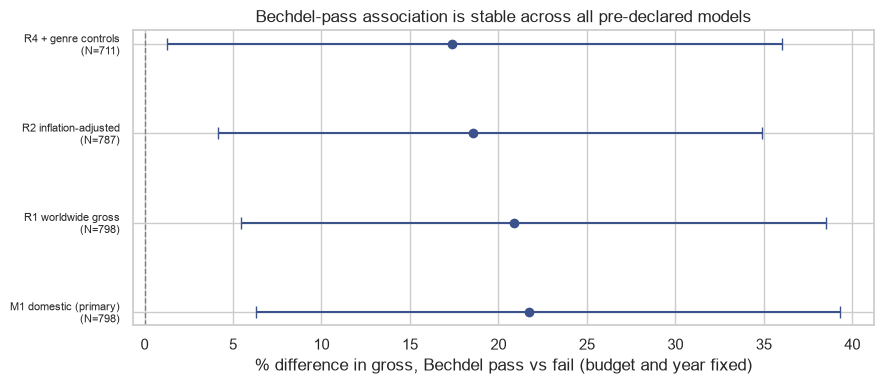

In [25]:
fig, ax = plt.subplots(figsize=(9, 4))
names, est, elo, ehi = [], [], [], []
for name, m in results.items():
    bb = m.params["pass_"]; l, h = m.conf_int().loc["pass_"]
    names.append(f"{name}\n(N={int(m.nobs)})")
    e = 100 * (10 ** bb - 1)
    est.append(e); elo.append(e - 100 * (10 ** l - 1)); ehi.append(100 * (10 ** h - 1) - e)
# errorbar wants distances from the point, not the CI bounds.
ax.errorbar(est, range(len(names)), xerr=[elo, ehi], fmt="o", capsize=4, color="#3b528b")
ax.axvline(0, color="grey", lw=1, ls="--")
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=8)
ax.set_xlabel("% difference in gross, Bechdel pass vs fail (budget and year fixed)")
ax.set_title("Bechdel-pass association is stable across all pre-declared models")
fig.tight_layout()
fig.savefig(FIGS / "final_regression_coefficient.png", dpi=150)
plt.show()

#### iii. Interpret your result

**M1 (primary).** Passing the Bechdel test is associated with **+21.7% higher
domestic gross** (95% CI +6.3% to +39.3%, p = 0.004, N = 798, R² = 0.454) once
production budget and release year are held fixed. The confidence interval
excludes zero across its full width, so the direction is reasonably firm even
though the interval is wide.

**This directly contradicts the unadjusted t-test in 4(c),** and the contradiction
is the finding. The raw comparison returned p = 0.727 with a point estimate of
−3.1%. Adding one control flips a null result into a positive one. The mechanism
is the suppression pattern established in 3: passing films are made on roughly
25% smaller budgets, and budget strongly drives gross, so in the raw comparison the
budget disadvantage cancels the performance advantage. Holding budget fixed reveals
that **passing films earn more than films of comparable cost**.

**M2 (secondary).** Female dialogue *share* shows essentially no association with
gross (+0.7% per 10 percentage points, CI −3.2% to +4.7%, p = 0.72). The two
predictors dissociate cleanly: the Bechdel *threshold* — two named women who talk
to each other about something other than a man — carries the association, while the
raw *quantity* of women's speech does not. A film can give women plenty of dialogue
without them ever speaking to one another.

**Robustness.** The association survives all four pre-declared checks: worldwide
gross (+20.9%), inflation-adjusted gross (+18.5%), and genre controls (+17.4%).
The ordinal model (R3) shows the effect concentrated at rating 3 rather than rising
steadily across ratings, which is what a genuine threshold effect should look like.

#### iv. Check for multicollinearity and analyze residuals (Optional)

Variance inflation factors (VIF > 5 would signal a multicollinearity problem)

  variable   VIF
     pass_ 1.019
log_budget 1.016
    year_c 1.003


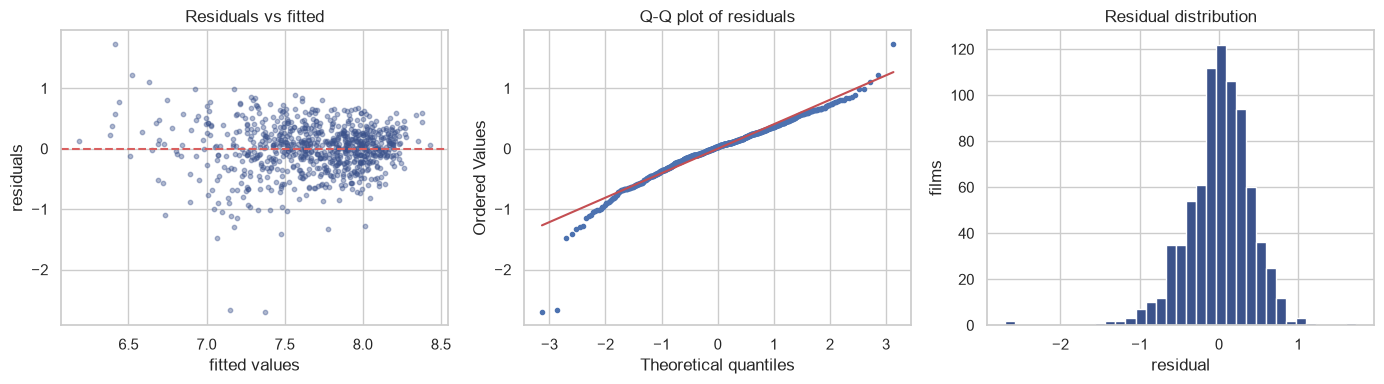


Jarque-Bera normality test on residuals: statistic = 838.49, p = 8.41e-183


In [26]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# VIF requires an explicit constant column.
X = df[["pass_", "log_budget", "year_c"]].assign(const=1.0)
vif = pd.DataFrame({
    "variable": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])],
})
print("Variance inflation factors (VIF > 5 would signal a multicollinearity problem)\n")
print(vif[vif["variable"] != "const"].round(3).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].scatter(m1.fittedvalues, m1.resid, s=10, alpha=0.4, color="#3b528b")
axes[0].axhline(0, color="#d95f5f", ls="--")
axes[0].set_xlabel("fitted values"); axes[0].set_ylabel("residuals")
axes[0].set_title("Residuals vs fitted")

stats.probplot(m1.resid, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set_markersize(3.0)
axes[1].set_title("Q-Q plot of residuals")

axes[2].hist(m1.resid, bins=35, color="#3b528b", edgecolor="white")
axes[2].set_xlabel("residual"); axes[2].set_ylabel("films")
axes[2].set_title("Residual distribution")
fig.tight_layout()
fig.savefig(FIGS / "final_residuals.png", dpi=150)
plt.show()

bp = stats.jarque_bera(m1.resid)
print(f"\nJarque-Bera normality test on residuals: statistic = {bp[0]:.2f}, p = {bp[1]:.3g}")

**Multicollinearity is not a problem.** All VIFs sit near 1, far below the
conventional threshold of 5. The predictors carry largely independent information,
so the coefficients are individually interpretable — unlike a model where two
near-identical regressors split an effect between them.

**Residuals are acceptable but not perfect.** The residuals-vs-fitted plot shows no
systematic curvature, so the linear functional form is reasonable, and the spread
is roughly constant across the fitted range. The Q-Q plot shows a left tail heavier
than normal, driven by films that underperformed their budgets badly, and
Jarque-Bera rejects normality. This is the same left-skew seen in 4(b), and it is
the reason **HC3 robust standard errors were pre-specified** rather than adopted
after inspecting the residuals — the inference does not depend on the residuals
being normal.

### b. Classification Model

#### i. Select an appropriate classification model based on the variable selected

**Target variable: `bechdel_pass`.** The regression above asked whether
representation predicts revenue. This section reverses the question: can a film's
**production characteristics** — how it was packaged and sold — predict whether it
represents women?

**Model selected: logistic regression.** The target is binary, and logistic
regression is the standard model for a binary outcome. It also returns
interpretable coefficients, so the model explains *which* characteristics move the
odds rather than only producing a prediction. The classes are almost exactly
balanced (50.1% pass), so accuracy is meaningful and no resampling is needed.

**Predictors: genre, MPAA rating, log budget, and release year.** Note what is
deliberately excluded: `pct_female_dialogue` and `pct_female_characters`. Those
measure how much women speak, and the Bechdel test is a measure of women speaking
to each other — a model built on them predicts well but only because it is a proxy
for the same construct. Restricting the predictors to production characteristics
keeps the question a real one.

**Encoding.** `genre` and `mpaa_rating` are categorical and one-hot encoded inside
a `ColumnTransformer`, with **Drama** and **R** as reference categories (the
largest group in each). Numeric predictors are standardized in the same pipeline,
so scaling is fit on training folds only and cannot leak.

The sample is the **711 films** with genre and MPAA rating recorded — the 87
missing rows are the WWU-sourced films documented in §2(a).

In [27]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

# Genre and MPAA are missing for the 87 WWU-sourced rows.
clf_df = df.dropna(subset=["genre", "mpaa_rating"]).copy()
CAT_FEATURES = ["genre", "mpaa_rating"]
NUM_FEATURES = ["log_budget", "year_c"]
X = clf_df[CAT_FEATURES + NUM_FEATURES]
y = clf_df["pass_"]

print("Target: bechdel_pass, predicted from production characteristics only")
print(f"  n = {len(clf_df)} films with genre and MPAA rating")
print(f"  class balance: {int((y == 0).sum())} fail / {int((y == 1).sum())} pass")
print(f"  majority-class baseline accuracy: {max(y.mean(), 1 - y.mean()):.4f}")

# One-hot the categoricals (Drama and R as reference), standardize the numerics.
pre = ColumnTransformer([
    ("cat", OneHotEncoder(drop=["Drama", "R"], handle_unknown="ignore"), CAT_FEATURES),
    ("num", StandardScaler(), NUM_FEATURES),
])
clf = Pipeline([("pre", pre),
                ("logreg", LogisticRegression(max_iter=2000, random_state=42))])

# stratify keeps the pass/fail ratio identical in both splits
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)[:, 1]
print(f"  train n = {len(X_train)},  test n = {len(X_test)}")

Target: bechdel_pass, predicted from production characteristics only
  n = 711 films with genre and MPAA rating
  class balance: 355 fail / 356 pass
  majority-class baseline accuracy: 0.5007
  train n = 533,  test n = 178


#### ii. Conduct the classification analysis and evaluate it with multiple metrics

In [28]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

print(f"MULTIPLE PERFORMANCE METRICS (held-out test set, n = {len(X_test)})\n")
print(f"  accuracy   {accuracy_score(y_test, y_pred):.4f}"
      f"     (baseline {accuracy_score(y_test, dummy.predict(X_test)):.4f})")
print(f"  precision  {precision_score(y_test, y_pred):.4f}"
      f"     of films predicted to pass, this fraction actually did")
print(f"  recall     {recall_score(y_test, y_pred):.4f}"
      f"     of films that actually pass, this fraction was caught")
print(f"  F1         {f1_score(y_test, y_pred):.4f}"
      f"     harmonic mean of precision and recall")
print(f"  ROC-AUC    {roc_auc_score(y_test, y_proba):.4f}"
      f"     threshold-independent ranking quality")

print("\n\nPer-class report:\n")
print(classification_report(y_test, y_pred, target_names=["fail (0)", "pass (1)"]))

cv = cross_val_score(clf, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=42),
                     scoring="accuracy")
print(f"5-fold cross-validated accuracy: {cv.mean():.4f} +/- {cv.std():.4f}")
print(f"  per fold: {np.round(cv, 4)}")

# Where does what little signal there is come from?
print("\n\nWhich predictors carry the signal (5-fold CV accuracy):")
for label, cols, cat in [("budget + year only", NUM_FEATURES, []),
                         ("genre + MPAA only", CAT_FEATURES, CAT_FEATURES),
                         ("all four", CAT_FEATURES + NUM_FEATURES, CAT_FEATURES)]:
    steps = []
    if cat:
        steps.append(("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat))
    num = [c for c in cols if c in NUM_FEATURES]
    if num:
        steps.append(("num", StandardScaler(), num))
    p = Pipeline([("pre", ColumnTransformer(steps)),
                  ("logreg", LogisticRegression(max_iter=2000, random_state=42))])
    s = cross_val_score(p, clf_df[cols], y, cv=StratifiedKFold(5, shuffle=True, random_state=42),
                        scoring="accuracy")
    print(f"  {label:20s} {s.mean():.4f}")

MULTIPLE PERFORMANCE METRICS (held-out test set, n = 178)

  accuracy   0.5562     (baseline 0.5000)
  precision  0.5625     of films predicted to pass, this fraction actually did
  recall     0.5056     of films that actually pass, this fraction was caught
  F1         0.5325     harmonic mean of precision and recall
  ROC-AUC    0.5816     threshold-independent ranking quality


Per-class report:

              precision    recall  f1-score   support

    fail (0)       0.55      0.61      0.58        89
    pass (1)       0.56      0.51      0.53        89

    accuracy                           0.56       178
   macro avg       0.56      0.56      0.56       178
weighted avg       0.56      0.56      0.56       178



5-fold cross-validated accuracy: 0.5879 +/- 0.0369
  per fold: [0.5594 0.5423 0.5775 0.6197 0.6408]


Which predictors carry the signal (5-fold CV accuracy):


  budget + year only   0.5527
  genre + MPAA only    0.5851


  all four             0.6062


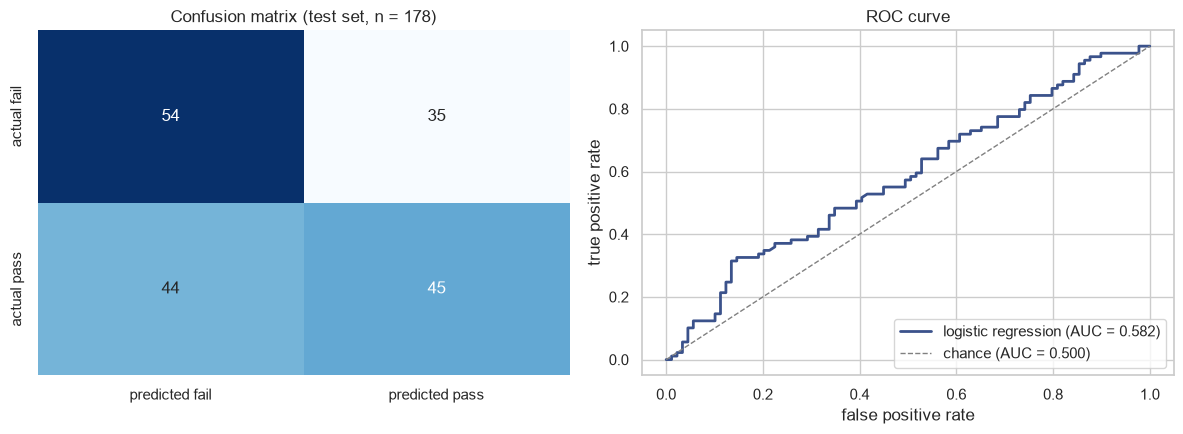

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["predicted fail", "predicted pass"],
            yticklabels=["actual fail", "actual pass"])
axes[0].set_title(f"Confusion matrix (test set, n = {len(X_test)})")

fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, color="#3b528b", lw=2,
             label=f"logistic regression (AUC = {roc_auc_score(y_test, y_proba):.3f})")
axes[1].plot([0, 1], [0, 1], color="grey", ls="--", lw=1, label="chance (AUC = 0.500)")
axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
axes[1].set_title("ROC curve"); axes[1].legend(loc="lower right")

fig.tight_layout()
fig.savefig(FIGS / "final_classification.png", dpi=150)
plt.show()

In [30]:
# Coefficients are log-odds relative to the reference film: a Drama, rated R,
# at mean budget and mean year.
names = list(clf.named_steps["pre"].get_feature_names_out())
coefs = pd.Series(clf.named_steps["logreg"].coef_[0], index=names).sort_values(ascending=False)
print("Logistic regression coefficients (log-odds; reference = Drama, rated R)\n")
print(coefs.round(3).to_string())

print("\n\nBechdel pass rate by genre:\n")
print(clf_df.groupby("genre")["bechdel_pass"]
      .agg(pass_rate="mean", films="size").round(3).to_string())
print("\nBechdel pass rate by MPAA rating:\n")
print(clf_df.groupby("mpaa_rating")["bechdel_pass"]
      .agg(pass_rate="mean", films="size").round(3).to_string())

Logistic regression coefficients (log-odds; reference = Drama, rated R)

cat__genre_Horror         1.241
cat__mpaa_rating_PG       1.052
cat__mpaa_rating_PG-13    0.773
num__year_c               0.124
cat__genre_Comedy        -0.029
cat__genre_Action        -0.040
cat__mpaa_rating_G       -0.042
num__log_budget          -0.303
cat__genre_Adventure     -0.393


Bechdel pass rate by genre:

           pass_rate  films
genre                      
Action         0.377    138
Adventure      0.414     87
Comedy         0.539    141
Drama          0.514    280
Horror         0.738     65

Bechdel pass rate by MPAA rating:

             pass_rate  films
mpaa_rating                  
G                0.200     10
PG               0.554     74
PG-13            0.548    239
R                0.469    388


#### iii. Interpret your result

**The model barely beats chance, and that is the finding.** Test accuracy is 55.6%
against a 50.0% baseline, with ROC-AUC 0.582; five-fold cross-validation gives
58.8% ± 3.7%. Those are weak numbers, and they answer the question directly:
**how a film is packaged tells you almost nothing about whether it represents
women.** Budget, release year, genre, and MPAA rating together move accuracy less
than nine points above a coin flip.

That has a practical consequence. Any process that tries to infer representation
from a film's commercial profile — its budget, its rating, its category — is
close to guessing. Representation has to be measured, not inferred.

**The little signal that exists is in category, not money.** Splitting the
predictors shows budget and year alone reach 55.3%, while genre and MPAA alone
reach 58.5%. The financial variables contribute least.

**Horror is the standout.** It carries the largest coefficient (+1.24 log-odds
against a Drama reference) and passes at **73.8%**, nearly double Action's 37.7%.
With 65 horror films in the sample the estimate is not precise, but the gap is
large and consistent with a genre whose conventions often centre on women.
Family-friendly ratings lean the same way: PG films pass at 55.4% and PG-13 at
54.8%, against 46.9% for R. The G-rated figure of 20.0% runs the other way, but
there are only 10 G-rated films in the sample and that estimate carries no weight.

**Budget carries a negative coefficient (−0.30)** even after genre and rating are
accounted for, which is the same relationship §3 and §5(a) found — bigger films
represent women less well. Seeing it survive in a completely different model, with
different predictors and a different outcome, is meaningful corroboration.

**Precision (0.563) and recall (0.506) are both near 0.5,** and the confusion
matrix is close to evenly split across all four cells. The model has no strong
bias in either direction; it simply lacks the information to separate the classes.

## 6. Advanced Analysis Techniques

### a. Clustering Analysis

#### i. Select an appropriate clustering method, with PCA to visualize the clusters

**Method selected: k-means.** The clustering variables are all continuous and
roughly ellipsoidal after the log transform, which is the situation k-means is
built for. It is also the method whose output is easiest to interpret — each
cluster is summarized by its center, which can be read back in original units.

**Standardization is mandatory here, not optional.** k-means minimizes Euclidean
distance, and `production_budget` spans tens of millions while
`pct_female_dialogue` spans 0 to 0.92. Without scaling, budget would account for
essentially all the distance and the clusters would be a budget ranking with the
representation variables contributing nothing.

**Clustering variables:** log budget, log domestic gross, female dialogue share,
and female character share. `bechdel_rating` is deliberately **excluded** so the
clusters can be compared against it afterwards as an external check — including it
would make that comparison circular.

**Choosing k.** Both an elbow plot and silhouette scores are used rather than
picking a number by eye.

Choosing k — elbow (inertia) and silhouette

 k   inertia  silhouette
 2 2001.4141      0.3553
 3 1564.0600      0.3241
 4 1312.9780      0.2675
 5 1146.2022      0.2474
 6 1038.1221      0.2377
 7  935.4576      0.2399


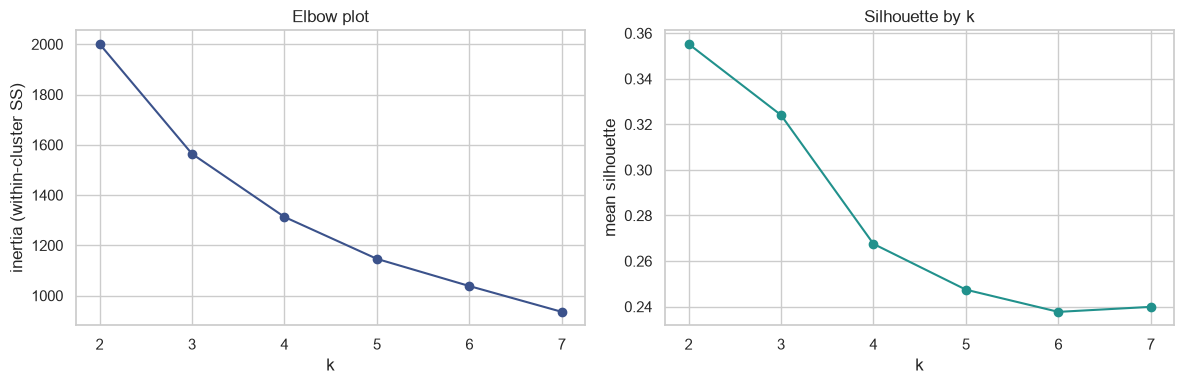

In [31]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

CLUSTER_FEATURES = ["log_budget", "log_dom",
                    "pct_female_dialogue", "pct_female_characters"]
# Standardize first: k-means uses Euclidean distance.
X_clust = StandardScaler().fit_transform(df[CLUSTER_FEATURES])

scan = []
# Inertia and silhouette across candidate k.
for k in range(2, 8):
    km_k = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_clust)
    scan.append({"k": k, "inertia": km_k.inertia_,
                 "silhouette": silhouette_score(X_clust, km_k.labels_)})
scan = pd.DataFrame(scan)
print("Choosing k — elbow (inertia) and silhouette\n")
print(scan.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(scan["k"], scan["inertia"], "o-", color="#3b528b")
axes[0].set_xlabel("k"); axes[0].set_ylabel("inertia (within-cluster SS)")
axes[0].set_title("Elbow plot")
axes[1].plot(scan["k"], scan["silhouette"], "o-", color="#21918c")
axes[1].set_xlabel("k"); axes[1].set_ylabel("mean silhouette")
axes[1].set_title("Silhouette by k")
fig.tight_layout()
fig.savefig(FIGS / "final_cluster_selection.png", dpi=150)
plt.show()

**k = 3 is chosen, and the reasoning needs stating because it is not the highest
silhouette score.** Silhouette peaks at k = 2 (0.355) with k = 3 close behind
(0.324). The two-cluster solution splits the sample into "big-budget, low female
dialogue" (504 films, 35.5% pass) and "small-budget, high female dialogue" (294
films, 73.5% pass) — but that conflates two different things, because it forces
budget and representation onto a single axis.

The three-cluster solution separates them, and the separation is real: it isolates
a group of **small-budget films that are also male-dominated**, which the
two-cluster solution hides inside its "small" group. Since the entire research
question is about how budget and representation relate, a solution that keeps them
distinct is more informative at a silhouette cost of 0.03. This is a judgment call
in favor of interpretability, and it is recorded as one rather than presented as
the number the metric picked.

In [32]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_clust)
df["cluster"] = kmeans.labels_

print(f"Cluster sizes: {df['cluster'].value_counts().sort_index().to_dict()}")
print(f"Mean silhouette at k=3: {silhouette_score(X_clust, kmeans.labels_):.4f}\n")

print("Cluster centers, read back in original units:\n")
centers = df.groupby("cluster").agg(
    films=("cluster", "size"),
    mean_budget_M=("production_budget", lambda s: s.mean() / 1e6),
    mean_domestic_M=("domestic_gross", lambda s: s.mean() / 1e6),
    pct_female_dialogue=("pct_female_dialogue", "mean"),
    pct_female_characters=("pct_female_characters", "mean"),
    bechdel_pass_rate=("bechdel_pass", "mean"),
)
print(centers.round(3).to_string())

Cluster sizes: {0: 192, 1: 424, 2: 182}
Mean silhouette at k=3: 0.3241

Cluster centers, read back in original units:

         films  mean_budget_M  mean_domestic_M  pct_female_dialogue  pct_female_characters  bechdel_pass_rate
cluster                                                                                                      
0          192         15.705           21.714                0.236                  0.294              0.438
1          424         83.818          130.488                0.182                  0.226              0.361
2          182         35.666           61.493                0.566                  0.522              0.868


PCA explained variance: PC1 0.549, PC2 0.308, cumulative 0.858

PCA loadings — what each component represents:

                         PC1    PC2
log_budget            -0.502  0.471
log_dom               -0.445  0.578
pct_female_dialogue    0.514  0.493
pct_female_characters  0.535  0.448


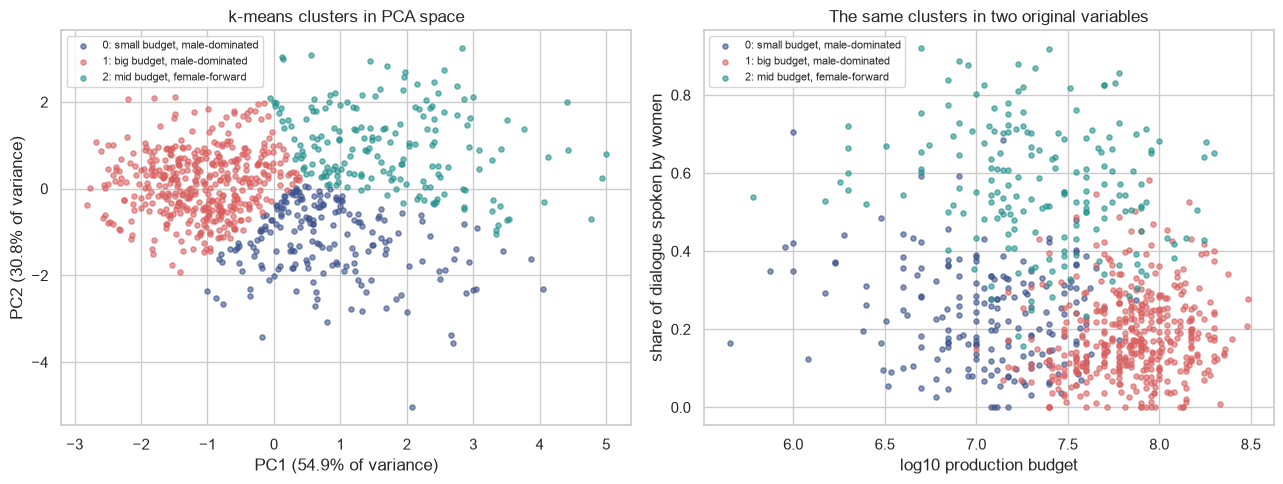

In [33]:
# PCA only projects 4 features to 2 for plotting; clusters used all 4.
pca = PCA(n_components=2).fit(X_clust)
coords = pca.transform(X_clust)
print(f"PCA explained variance: PC1 {pca.explained_variance_ratio_[0]:.3f}, "
      f"PC2 {pca.explained_variance_ratio_[1]:.3f}, "
      f"cumulative {pca.explained_variance_ratio_.sum():.3f}\n")
print("PCA loadings — what each component represents:\n")
print(pd.DataFrame(pca.components_.T, index=CLUSTER_FEATURES,
                   columns=["PC1", "PC2"]).round(3).to_string())

labels = {0: "0: small budget, male-dominated",
          1: "1: big budget, male-dominated",
          2: "2: mid budget, female-forward"}
palette = {0: "#3b528b", 1: "#d95f5f", 2: "#21918c"}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for c in sorted(df["cluster"].unique()):
    m = df["cluster"] == c
    axes[0].scatter(coords[m, 0], coords[m, 1], s=14, alpha=0.6,
                    color=palette[c], label=labels[c])
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
axes[0].set_title("k-means clusters in PCA space")
axes[0].legend(fontsize=8, loc="best")

for c in sorted(df["cluster"].unique()):
    m = df["cluster"] == c
    axes[1].scatter(df.loc[m, "log_budget"], df.loc[m, "pct_female_dialogue"],
                    s=14, alpha=0.6, color=palette[c], label=labels[c])
axes[1].set_xlabel("log10 production budget")
axes[1].set_ylabel("share of dialogue spoken by women")
axes[1].set_title("The same clusters in two original variables")
axes[1].legend(fontsize=8, loc="best")

fig.tight_layout()
fig.savefig(FIGS / "final_clusters.png", dpi=150)
plt.show()

#### ii. Evaluate the model and interpret the grouping

In [34]:
print("EXTERNAL VALIDATION — cluster membership vs Bechdel outcome")
print("(bechdel_rating was NOT used to build the clusters)\n")
ct = pd.crosstab(df["cluster"], df["bechdel_pass"], margins=True)
print(ct.to_string())
print("\nBechdel pass rate by cluster:")
print((df.groupby("cluster")["bechdel_pass"].mean()).round(3).to_string())

chi2_cl, p_cl, dof_cl, _ = stats.chi2_contingency(
    pd.crosstab(df["cluster"], df["bechdel_pass"]))
print(f"\nchi-squared test of independence: chi2 = {chi2_cl:.2f}, "
      f"df = {dof_cl}, p = {p_cl:.3g}")

EXTERNAL VALIDATION — cluster membership vs Bechdel outcome
(bechdel_rating was NOT used to build the clusters)

bechdel_pass  False  True  All
cluster                       
0               108    84  192
1               271   153  424
2                24   158  182
All             403   395  798

Bechdel pass rate by cluster:
cluster
0    0.438
1    0.361
2    0.868

chi-squared test of independence: chi2 = 134.43, df = 2, p = 6.43e-30


**Evaluation.** Mean silhouette at k = 3 is 0.324. On the usual reading that is
weak-to-moderate structure: the clusters are real but not sharply separated, which
is expected for film data where the underlying variables are continuous and there
are no natural categories. PC1 and PC2 together capture 85.8% of the variance, so
the two-dimensional plot is a fair representation rather than a lossy projection.

The loadings show what the axes mean. **PC1 loads negatively on budget and gross
(−0.502, −0.445) and positively on the two representation measures (0.514,
0.535)** — it is a single "commercial scale versus female presence" axis, and the
fact that these load in opposite directions on the same component is the
confounding relationship appearing yet again. PC2 loads positively on everything,
so it is an overall-magnitude axis.

**Interpreting the three groups:**

| Cluster | n | Mean budget | Mean domestic | Female dialogue | Bechdel pass rate |
|---|---|---|---|---|---|
| 0 — small budget, male-dominated | 192 | \$15.7M | \$21.7M | 23.6% | 43.8% |
| 1 — big budget, male-dominated | 424 | \$83.8M | \$130.5M | 18.2% | 36.1% |
| 2 — mid budget, female-forward | 182 | \$35.7M | \$61.5M | 56.6% | 86.8% |

**The grouping is substantively meaningful, and cluster 0 is the reason k = 3 was
worth the silhouette cost.** Clusters 0 and 1 are separated almost entirely by
money — one is small films, the other blockbusters — yet both give women under a
quarter of the dialogue and both fail the Bechdel test more often than not. **Being
a small, inexpensive film does not make a film female-forward.** Cluster 2 is the
distinct group: mid-budget films where women speak 56.6% of the dialogue, passing
the Bechdel test at 86.8%.

**The external validation is strong.** Bechdel rating played no part in forming
these clusters, yet pass rates across them run 36.1%, 43.8%, and 86.8%, and a
chi-squared test rejects independence decisively. The dialogue structure the
algorithm found on its own tracks the volunteer-assigned Bechdel ratings — two
independently produced measures of representation agreeing with each other, which
is meaningful evidence that both are capturing something real.

One limitation worth noting: cluster 2 sits at *middle* budgets, not low ones. The
female-forward films in this sample are not micro-budget independents; they are
mid-scale commercial releases.

### b. Machine Learning approach to Regression or Classification

#### i. Apply a regression model using a machine learning approach

This section re-runs the **regression** question from 5(a) — predicting log₁₀
domestic gross — with a machine learning method, so the two approaches can be
compared directly on the same variables. Per the project guidelines, **k-fold
cross-validation is used rather than a single train-test split**, which gives a
more reliable performance estimate by evaluating on every observation exactly once
across five folds instead of trusting one arbitrary partition.

**Model selected: random forest regressor.** It is a natural contrast to OLS
because it relaxes the two assumptions OLS depends on — it fits non-linear
relationships without being told to, and it captures interactions between
predictors automatically. If the true relationship between budget and gross has
curvature or depends on other variables, the forest can find it and OLS cannot.

Both models use the same predictors and the same fold assignments, so the
comparison isolates the algorithm rather than the setup. OLS is wrapped in a
pipeline with a scaler purely for symmetry; it does not affect linear regression
results.

In [35]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold

ML_FEATURES = ["log_budget", "year_c", "pct_female_dialogue",
               "pct_female_characters", "pass_"]
X_ml = df[ML_FEATURES]
y_ml = df["log_dom"]

# Identical folds for both models so the comparison is like-for-like.
folds = KFold(n_splits=5, shuffle=True, random_state=42)

ols_pipe = Pipeline([("scaler", StandardScaler()), ("ols", LinearRegression())])
forest = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)

ols_r2 = cross_val_score(ols_pipe, X_ml, y_ml, cv=folds, scoring="r2")
rf_r2 = cross_val_score(forest, X_ml, y_ml, cv=folds, scoring="r2")
# sklearn returns RMSE negated; flip the sign back.
ols_rmse = -cross_val_score(ols_pipe, X_ml, y_ml, cv=folds,
                            scoring="neg_root_mean_squared_error")
rf_rmse = -cross_val_score(forest, X_ml, y_ml, cv=folds,
                           scoring="neg_root_mean_squared_error")

print("5-FOLD CROSS-VALIDATED PERFORMANCE (identical folds for both models)\n")
print(pd.DataFrame({
    "mean R2": [ols_r2.mean(), rf_r2.mean()],
    "std R2": [ols_r2.std(), rf_r2.std()],
    "mean RMSE (log10)": [ols_rmse.mean(), rf_rmse.mean()],
}, index=["OLS (traditional)", "Random forest (ML)"]).round(4).to_string())

print(f"\nOLS    per-fold R2: {np.round(ols_r2, 3)}")
print(f"Forest per-fold R2: {np.round(rf_r2, 3)}")
print(f"\nDifference in mean R2 (forest - OLS): {rf_r2.mean() - ols_r2.mean():+.4f}")

5-FOLD CROSS-VALIDATED PERFORMANCE (identical folds for both models)

                    mean R2  std R2  mean RMSE (log10)
OLS (traditional)    0.4406  0.1020             0.4156
Random forest (ML)   0.3655  0.1083             0.4427

OLS    per-fold R2: [0.387 0.545 0.39  0.306 0.574]
Forest per-fold R2: [0.273 0.475 0.325 0.242 0.512]

Difference in mean R2 (forest - OLS): -0.0751


#### ii. Evaluate the model performance metrics and interpret the results

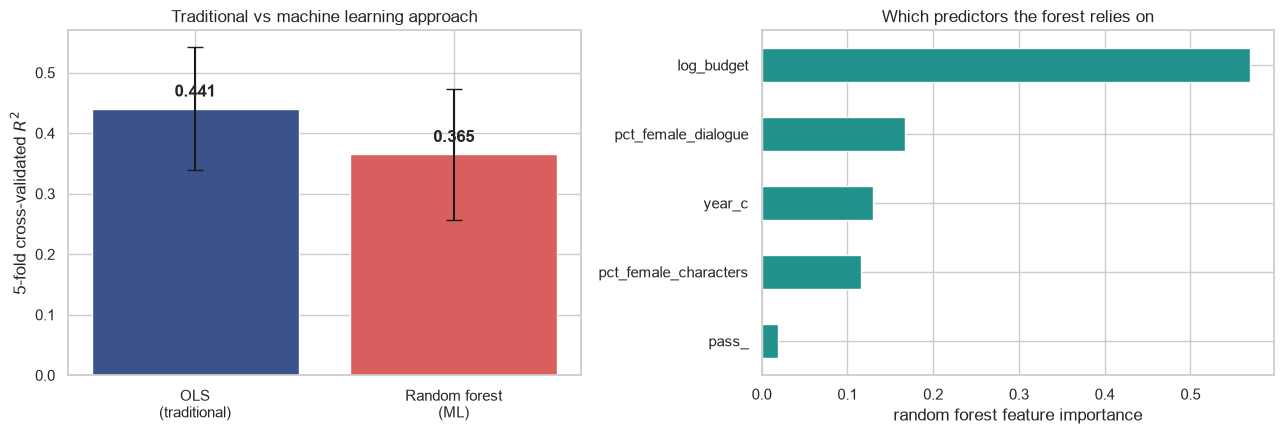

Random forest feature importances:

log_budget               0.5690
pct_female_dialogue      0.1671
year_c                   0.1297
pct_female_characters    0.1158
pass_                    0.0185


In [36]:
# Refit on all rows to read feature importances.
forest_full = RandomForestRegressor(n_estimators=300, random_state=42,
                                    n_jobs=-1).fit(X_ml, y_ml)
importances = pd.Series(forest_full.feature_importances_,
                        index=ML_FEATURES).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(["OLS\n(traditional)", "Random forest\n(ML)"],
            [ols_r2.mean(), rf_r2.mean()],
            yerr=[ols_r2.std(), rf_r2.std()], capsize=6,
            color=["#3b528b", "#d95f5f"])
axes[0].set_ylabel("5-fold cross-validated $R^2$")
axes[0].set_title("Traditional vs machine learning approach")
for i, v in enumerate([ols_r2.mean(), rf_r2.mean()]):
    axes[0].text(i, v + 0.02, f"{v:.3f}", ha="center", fontweight="bold")

importances.sort_values().plot.barh(ax=axes[1], color="#21918c")
axes[1].set_xlabel("random forest feature importance")
axes[1].set_title("Which predictors the forest relies on")

fig.tight_layout()
fig.savefig(FIGS / "final_ml_comparison.png", dpi=150)
plt.show()

print("Random forest feature importances:\n")
print(importances.round(4).to_string())

**The machine learning model performs worse than ordinary least squares, and that
is the finding rather than a failure to report.** Cross-validated R² is **0.441 for
OLS against 0.366 for the random forest** — the traditional method wins by 7.5
points, using the same predictors and the same folds. RMSE agrees.

**Why the more flexible model loses.** A random forest's advantage is capturing
curvature and interactions. Here there is little of either to capture: after the
log transform, the budget–gross relationship is close to genuinely linear, which
5(a)'s residual plot already showed. So the forest gains nothing from its
flexibility while paying its usual costs — it fits piecewise-constant steps rather
than a smooth line, it cannot extrapolate beyond the range of the training folds,
and with 798 rows and five predictors it has enough freedom to fit fold-specific
noise. When the true relationship is close to linear, the linear model is not a
simplification to be improved on; it is the correct specification.

**The per-fold spread deserves attention.** OLS ranges from 0.306 to 0.574 across
folds and the forest from 0.242 to 0.512 — both vary by more than 0.25 depending on
the split. This is exactly why the guidelines require cross-validation for machine
learning regression: had this been reported from a single lucky train-test split,
either model could have been made to look substantially better or worse than it is.
The honest headline is a mean with its spread, not a best fold.

**Feature importance and statistical significance measure different things, and
this model shows the gap clearly.** `log_budget` dominates the forest at 0.569,
while `pass_` — the Bechdel variable, and the entire point of the project — scores
0.019, essentially nothing. Yet 5(a) found that same variable statistically
significant at +21.7% with p = 0.004.

Both results are correct because they answer different questions. Importance asks
*how much does this variable help me predict an unknown film's gross?* — and the
answer is barely at all, because budget explains most of what is predictable.
The regression coefficient asks *among films with the same budget and release year,
how much do passing films differ?* — and the answer is meaningfully. A variable can
carry a real, consistent conditional association while contributing almost nothing
to raw predictive accuracy. Reading the feature importance as evidence that the
Bechdel result is unimportant would be a straightforward misinterpretation, and
the contrast between these two numbers is a good illustration of why prediction and
explanation are separate goals.

## 7. Data Storytelling

Please see PDF submitted alongside .ipynb file.

## 8. Documentation

### a. Documentation of the analysis process

Every section above states the choice made, the reason for it, and the alternative
rejected. The full acquisition history — including two sources that had to be
replaced mid-project when they went offline — is recorded in
`data/raw/README_provenance.md`.

### b. Limitations of the analysis and assumptions made

These are stated as first-class results rather than caveats, because several of
them bound what the headline number means.

1. **Association, not causation.** Nothing here identifies a causal effect. Films
   that pass the Bechdel test may differ from films that fail in ways not captured
   by budget and year — genre conventions, casting, marketing spend, or director
   experience. The estimate is a description of a pattern, not a prediction about
   what would happen if a film changed its script.
2. **Triple selection funnel.** The sample is the intersection of three sources and
   skews progressively toward larger films at every stage (\$93M → \$106M → \$125M
   mean gross). Results describe well-documented commercial releases, not films in
   general, and the range restriction likely *attenuates* the estimated
   association.
3. **Volunteer-coded outcome.** Bechdel ratings come from site visitors, not trained
   coders, and the 2021 mirror carries no `dubious` flag to mark disputed entries.
4. **Binary gender coding.** The dialogue data codes every character male or female
   against IMDb, erasing non-binary identities and introducing error for
   ambiguously named characters.
5. **The Bechdel test is a coarse instrument.** It measures a minimum threshold, not
   quality of representation. A film can pass on a single throwaway exchange, and
   an excellent film about one woman necessarily fails.
6. **A frozen data source.** bechdeltest.com's API was permanently disabled during
   this project (HTTP 410), so the 2021 mirror is final — films rated after March
   2021 are absent. The 2015 cutoff is set by the Pudding data.
7. **Wide confidence interval.** The +21.7% estimate spans +6.3% to +39.3%. The
   direction is reasonably firm; the magnitude is not precisely pinned down.
8. **Nominal dollars.** The primary outcome uses nominal gross, relying on the year
   control to absorb price-level drift. The inflation-adjusted robustness check
   (+18.5%) confirms this choice does not drive the result.

---

## References

Anderson, H., & Daniels, M. (2016). *Film dialogue from 2,000 screenplays, broken
down by gender and age.* The Pudding. https://pudding.cool/2017/03/film-dialogue/

Bechdel Test Movie List. (2021). *Bechdel test data* [Data set]. Accessed via the
TidyTuesday 2021-03-09 mirror. https://bechdeltest.com/ (CC BY-NC 3.0)

Molin, S. (2021). *Hands-on data analysis with pandas* (2nd ed.). Packt Publishing.

Nash Information Services. (2018, 2023). *Movie budgets and financial performance
records* [Data set]. The Numbers. Accessed via the TidyTuesday 2018-10-23 snapshot
and the WWU DATA 311 course mirror. https://www.the-numbers.com/

Seabold, S., & Perktold, J. (2010). Statsmodels: Econometric and statistical
modeling with Python. *Proceedings of the 9th Python in Science Conference.*

Virtanen, P., et al. (2020). SciPy 1.0: Fundamental algorithms for scientific
computing in Python. *Nature Methods, 17*, 261–272.